# Лабораторная работа 1. RLC-цепь: модель ОДУ в частотной области

**Тема 6 списка:** *ODE models in the frequency domain: RLC circuit in electrical systems.*

Ноутбук — отчёт о вычислительном эксперименте. Весь код классов и функций вынесен в модуль [`rlcfreq`](../rlcfreq) (тесты — в [`tests/`](../tests)); здесь только вызовы, графики и их описание. Ноутбук воспроизводится командой `make notebook` (данные скачиваются по HTTP, контрольные суммы SHA‑256 проверяются).

**Содержание**
0. Описание вычислительного эксперимента и источники данных
1. Модели: учебная (ОДУ 2‑го порядка) и журнальная (дробная $L^{\beta}C^{\alpha}$); утверждения с доказательствами
2. Символьные представления: дерево SymPy, грамматика схем, граф схемы и узловой анализ, передаточная функция, DAG суперпозиции, словарь и матрица связей
3. Векторные поля $\mathbb R^3\to\mathbb R^3$: дивергенция, ротор, произведения, теорема Лиувилля
4. Данные из трёх источников и их 3D‑представление с учётом времени
5. Вектор параметров, выбор оптимизатора и солвера
6. Подгонка параметров: тестовые цепи, литий‑ионный элемент (299 спектров), СВЧ‑резонаторы
7. Ошибки аппроксимации и сравнение моделей
8. Временная область: решения уравнений в 3D
9. Выводы и задел для лабораторных 2–3

## 0. Описание вычислительного эксперимента

**Объект.** Линейная RLC‑цепь, описываемая ОДУ второго порядка, и её обобщения — эквивалентные схемы из элементов $R, L, C$ и элементов постоянной фазы. В частотной области ОДУ превращается в алгебраическое соотношение $V(s)=Z(s)\,I(s)$; измеряемые величины — комплексный импеданс $Z(i\omega)$ (импедансная спектроскопия, EIS) или коэффициент передачи $S_{21}(f)$ (векторный анализатор цепей, VNA).

**Вопрос.** Достаточно ли учебной модели с идеальными элементами (вариант *T*, textbook), или данные требуют журнальной модификации с дробными производными (вариант *J*, journal: конденсатор Westerlund–Ekstam / CPE и дробная катушка Radwan–Salama)? Ответ ищется на трёх физически разных объектах, чтобы проверить вариативность уравнения.

**Гипотезы.**
* **H1.** Для цепи из дискретных компонентов учебная модель $R_0 + sL_0 + R_1/(1+sR_1C_1)$ описывает данные с относительной ошибкой порядка $10^{-3}$, а показатель CPE близок к 1.
* **H2.** Для литий‑ионного элемента учебная RC‑модель систематически ошибается (сжатые дуги, диффузионный «хвост»), а CPE‑модель уменьшает ошибку на порядок; параметры дрейфуют с числом циклов согласованно с деградацией ёмкости.
* **H3.** Для мод полоскового резонатора модели *T* и *J* по одной моде неразличимы, но *J* (диэлектрик с постоянным углом потерь) предсказывает **не зависящую от частоты добротность** мод, тогда как сосредоточенное сопротивление ($R=\mathrm{const}$) даёт $Q\propto f$, а скин‑эффект — $Q\propto\sqrt f$.

**План.** (1) вывести $Z(s)$ из ОДУ символьно, сформулировать модификацию и доказать её свойства; (2) построить символьные и графовые представления; (3) загрузить данные по HTTP; (4) вынести параметры в вектор $\boldsymbol\theta$ с ожидаемыми значениями; (5) выбрать оптимизатор и солвер по численному сравнению; (6) оценить $\hat{\boldsymbol\theta}$, ошибки и неопределённость; (7) вернуться во временную область.

**Критерии качества.** Взвешенная сумма квадратов $S(\boldsymbol\theta)=\sum_k |\hat Z_k-Z_k|^2/|Z_k|^2$ (относительная ошибка), RMSE $=\sqrt{S/n}$, информационные критерии AIC/BIC, обусловленность якобиана (идентифицируемость), стандартные ошибки параметров.

**Воспроизводимость.** Данные — по закреплённым коммитам GitHub (SHA‑256 в `rlcfreq/data.py`); все стохастические оптимизаторы с `seed=0`; версии библиотек печатаются ниже.

In [1]:
import sys, json, time, platform, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

import numpy as np, pandas as pd, sympy as sp, networkx as nx, scipy, matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

import rlcfreq
from rlcfreq import circuit, models, symbolic as S, fields, fitting, timedomain as td, data, resonance
from rlcfreq.graph import ExpressionDAG, circuit_graph
from rlcfreq.plotting import (PALETTE, BLUES, apply_style, nyquist, draw_dag, draw_adjacency,
                              draw_circuit_graph, savefig)

apply_style()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
warnings.filterwarnings("ignore", category=RuntimeWarning)
SEED = 0
print("python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| sympy", sp.__version__, "| networkx", nx.__version__, "| matplotlib", matplotlib.__version__,
      "| pandas", pd.__version__, "| rlcfreq", rlcfreq.__version__)

python 3.13.16 | numpy 2.5.3 | scipy 1.18.1 | sympy 1.14.0 | networkx 3.6.1 | matplotlib 3.11.2 | pandas 3.0.5 | rlcfreq 1.0.0


### Источники данных (загрузка по HTTP)

| ключ | источник | что берём | физика |
|---|---|---|---|
| `zhang2020` | Zhang Y. et al., *Nature Communications* **11**, 1706 (2020); репозиторий кода статьи | 299 спектров EIS элемента 35C02 (LiCoO$_2$/графит, 45 мА·ч, 35 °C), циклы 2…598, 60 частот 20 кГц…0,02 Гц; ёмкость по циклам | электрохимическая «RLC»-цепь, медленное время = старение |
| `impedancepy` | Murbach M. D. et al., *JOSS* **5**, 2349 (2020); репозиторий impedance.py | 3 физические тестовые цепи $R_0$–$(R_1\|C_1)$ × 2 повтора, 1 Гц…300 кГц, с временем регистрации каждой точки | дискретные компоненты + паразитная индуктивность выводов |
| `skrf` | Arsenovic A. et al., *IEEE Microwave Magazine* **23**(1), 98–105 (2022); репозиторий scikit-rf | $S$-параметры полосковых резонаторов 36/72/144 мм, Keysight N5242A, 1–5 ГГц | моды линии = последовательные RLC‑контуры |

Таблица ниже собрана из реестра модуля: URL закреплённого коммита и контрольная сумма каждого файла.

In [2]:
data.sources_table()

,source,file,url,sha256,license
0,zhang2020,zhang2020_Code-Matlab.zip,https://raw.githubusercontent.com/YunweiZhang/...,7d6ab9b3d48a2ead…,data: CC BY 4.0 (Zenodo record)
1,impedancepy,impedancepy_Circuit1_EIS_1.z,https://raw.githubusercontent.com/ECSHackWeek/...,00c920ac9224ddee…,MIT
2,impedancepy,impedancepy_Circuit1_EIS_2.z,https://raw.githubusercontent.com/ECSHackWeek/...,aefc7bfa3c892535…,MIT
3,impedancepy,impedancepy_Circuit2_EIS_1.z,https://raw.githubusercontent.com/ECSHackWeek/...,2bb61593f88bc5cf…,MIT
4,impedancepy,impedancepy_Circuit2_EIS_2.z,https://raw.githubusercontent.com/ECSHackWeek/...,351507e00a4d322e…,MIT
5,impedancepy,impedancepy_Circuit3_EIS_1.z,https://raw.githubusercontent.com/ECSHackWeek/...,3324a5ce6e9abb35…,MIT
6,impedancepy,impedancepy_Circuit3_EIS_2.z,https://raw.githubusercontent.com/ECSHackWeek/...,93731fc0606c3038…,MIT
7,impedancepy,impedancepy_exampleData.csv,https://raw.githubusercontent.com/ECSHackWeek/...,7a6185b5e95e7457…,MIT
8,skrf,skrf_resonator_36mm.s2p,https://raw.githubusercontent.com/scikit-rf/sc...,9fd37c4871cc79aa…,BSD-3-Clause
9,skrf,skrf_resonator_72mm.s2p,https://raw.githubusercontent.com/scikit-rf/sc...,7d28c2928d7d0e7e…,BSD-3-Clause


## 1. Модели

### 1.1 Учебная модель: ОДУ второго порядка → преобразование Лапласа → $Z(s)$

Последовательная RLC‑цепь, источник напряжения $v(t)$, заряд конденсатора $q(t)$, ток $i=\dot q$:
$$
L\,\ddot q + R\,\dot q + \frac{q}{C} = v(t),\qquad q(0)=\dot q(0)=0. \tag{T}
$$
Ниже SymPy применяет преобразование Лапласа к левой части, подставляет нулевые начальные условия и возвращает $Z(s)=V(s)/I(s)$, $I(s)=sQ(s)$. Ограничение на мнимую ось $s=i\omega$ — это и есть «частотная область»:
$$Z_T(i\omega)=R+i\Big(\omega L-\frac{1}{\omega C}\Big).$$
Сеть из элементов собирается по правилам: последовательное соединение — сумма импедансов, параллельное — сумма проводимостей.

In [3]:
ode = S.series_rlc_ode()["ode"]
Z_T = S.impedance_from_ode()
display(ode)
Z_T

Eq(L*Derivative(q(t), (t, 2)) + R*Derivative(q(t), t) + q(t)/C, v(t))

L*s + R + 1/(C*s)

### 1.2 Журнальная модификация: дробные элементы $L^{\beta}C^{\alpha}$

* Westerlund & Ekstam (*IEEE Trans. Dielectr. Electr. Insul.* **1**(5), 826–839, 1994): ток реального конденсатора $i(t)=C_\alpha\,D^{\alpha}v(t)$, $0<\alpha\le 1$ (закон Кюри–фон Швейдлера) ⇒ $Z=1/(Q s^{\alpha})$ — **элемент постоянной фазы (CPE)**; в импедансной спектроскопии это стандартный элемент эквивалентных схем (Wang S. et al., *Nature Reviews Methods Primers* **1**, 41, 2021).
* Radwan & Salama (*IEEE Trans. Circuits Syst. I* **58**(10), 2388–2397, 2011): дробная катушка $v=L_\beta D^{\beta} i$ и дробная последовательная цепь $L_\beta C_\alpha$.

Дробная последовательная RLC‑цепь:
$$
L\,D^{\beta} i + R\,i + \frac{1}{Q}\,D^{-\alpha} i = v(t),\qquad Z_J(s)=R+L s^{\beta}+\frac{1}{Q s^{\alpha}}. \tag{J}
$$

**Явные допущения.** (A1) малосигнальный линейный стационарный режим; (A2) нулевая предыстория, при которой производные Капуто, Римана–Лиувилля и Грюнвальда–Летникова совпадают и $\mathcal L\{D^{\gamma}f\}=s^{\gamma}F(s)$; (A3) главная ветвь $(i\omega)^{\gamma}=\omega^{\gamma}e^{i\gamma\pi/2}$; (A4) $R\ge 0$, $L,Q>0$, $\alpha,\beta\in(0,1]$.

In [4]:
fr = S.fractional_series_rlc()
re_J, im_J = S.split_real_imag(fr["Z"])
display(fr["Z"], sp.Eq(sp.Symbol("Re Z_J"), re_J), sp.Eq(sp.Symbol("Im Z_J"), im_J))
print("Z_J при alpha = beta = 1, Q = C:", fr["reduces_to"])

L*s**beta + R + 1/(Q*s**alpha)

Eq(Re Z_J, L*omega**beta*cos(pi*beta/2) + R + cos(pi*alpha/2)/(Q*omega**alpha))

Eq(Im Z_J, L*omega**beta*sin(pi*beta/2) - sin(pi*alpha/2)/(Q*omega**alpha))

Z_J при alpha = beta = 1, Q = C: L*s + R + 1/(C*s)


### 1.3 Утверждения и доказательства

**Утверждение 1 (вложенность).** $Z_J\big|_{\alpha=\beta=1,\;Q=C}=Z_T$.
*Доказательство:* подстановка (проверено символьно выше). Следствие: модели вложены, их можно сравнивать по правдоподобию. *Оговорка:* значение $\alpha=1$ лежит на границе допустимого множества, поэтому асимптотика $\chi^2$ для отношения правдоподобия неприменима (Self & Liang, 1987); AIC/BIC используем как описательные меры. ∎

**Утверждение 2 (пассивность).** Пусть сеть собрана из элементов $R, L, C, Q, L_f$ последовательными и параллельными соединениями, и выполнены (A3)–(A4). Тогда $\operatorname{Re}Z(i\omega)\ge 0$ при всех $\omega>0$.
*Доказательство.* Индукция по дереву разбора схемы. База: $\arg(i\omega)^{\gamma}=\gamma\pi/2\in[0,\pi/2]$ при $\gamma\in[0,1]$, $\arg(i\omega)^{-\alpha}\in[-\pi/2,0]$, поэтому импеданс каждого элемента лежит в замкнутой правой полуплоскости $\bar{\mathbb C}_+$. Шаг: $\bar{\mathbb C}_+$ замкнута относительно сложения (последовательное соединение) и относительно $z\mapsto 1/z$ при $z\neq 0$, так как $\operatorname{Re}(1/z)=\operatorname{Re}z/|z|^2$; значит, $1/\sum_k z_k^{-1}\in\bar{\mathbb C}_+$ (параллельное соединение). ∎
Замечание: при $\alpha>1$ база нарушается — элемент вносит отрицательное сопротивление; поэтому граница $\alpha\le 1$ в оптимизации — физическое ограничение, а не численный приём.

**Утверждение 3 (резонанс).** При (A3)–(A4) функция $\operatorname{Im}Z_J(i\omega)$ имеет единственный нуль
$$\omega_r=\left[\frac{\sin(\alpha\pi/2)}{Q\,L\,\sin(\beta\pi/2)}\right]^{1/(\alpha+\beta)},$$
переходящий в $1/\sqrt{LC}$ при $\alpha=\beta=1$.
*Доказательство.* $\operatorname{Im}Z_J=L\sin(\beta\pi/2)\,\omega^{\beta}-\sin(\alpha\pi/2)\,\omega^{-\alpha}/Q$. Оба слагаемых строго возрастают по $\omega$ (коэффициенты положительны при $\alpha,\beta\in(0,1]$), предел при $\omega\to 0^+$ равен $-\infty$, при $\omega\to\infty$ — $+\infty$; по теореме о промежуточном значении нуль существует, по монотонности он единственный. Решение уравнения даёт формулу. ∎

**Утверждение 4 (CPE и тангенс угла потерь).** Для $Z=1/(Qs^{\alpha})$ отношение $\tan\delta:=\operatorname{Re}Z/(-\operatorname{Im}Z)=\cot(\alpha\pi/2)$ не зависит от частоты.
*Доказательство:* $Z(i\omega)=\omega^{-\alpha}\big(\cos\tfrac{\alpha\pi}{2}-i\sin\tfrac{\alpha\pi}{2}\big)/Q$. ∎
Следствие: ветвь «$L$ + CPE» без резистора имеет на резонансе добротность $Q_{\rm res}=\tan(\alpha\pi/2)$, не зависящую от $L$, $Q$ и $\omega_r$.

**Утверждение 5 (добротность мод линии).** Пусть отрезок однородной TEM‑линии длины $\ell$ с волновым сопротивлением $Z_0$ и малыми потерями ($\alpha_{\rm att}\ell\ll 1$) работает вблизи последовательного резонанса $n$‑й моды, $\beta\ell=n\pi$. Тогда в первом порядке по расстройке $Z\approx Z_0\alpha_{\rm att}\ell+i\,Z_0\,n\pi\,\Delta\omega/\omega_n$, т.е. эквивалентная последовательная цепь имеет $L_n=Z_0\pi/(2\omega_1)$ (одинакова для всех мод) и $R_n=Z_0\alpha_{\rm att}(\omega_n)\ell$, откуда $Q_n=\omega_nL_n/R_n\propto \omega_n/\alpha_{\rm att}(\omega_n)$.
*Доказательство.* $Z_{\rm in}=Z_0\tanh\big((\alpha_{\rm att}+i\beta)\ell\big)$; при $\beta\ell=n\pi+\Delta\beta\,\ell$ и $\tanh(i n\pi)=0$ разложение Тейлора даёт $Z_{\rm in}\approx Z_0(\alpha_{\rm att}\ell+i\Delta\beta\,\ell)$, а $\Delta\beta\,\ell=\ell\Delta\omega/v_p=n\pi\Delta\omega/\omega_n$. Сравнение с $R+2iL\Delta\omega$ даёт $L_n$ и $R_n$. ∎
Следствие (проверяемый прогноз): $\ln Q_n=s\ln f_n+\mathrm{const}$ с наклоном $s=1$ при $R=\mathrm{const}$ (учебная модель), $s=1/2$ при скин‑эффекте ($\alpha_{\rm att}\propto\sqrt f$), $s=0$ при диэлектрике с постоянным $\tan\delta$ ($\alpha_{\rm att}\propto f$), что согласуется с утверждением 4.

**Утверждение 6 (идентифицируемость).** (a) Для (T) значения $Z(i\omega_1)$, $Z(i\omega_2)$ при $\omega_1\ne\omega_2$ однозначно определяют $(R,L,C)$. (b) Если схема содержит $m\ge2$ последовательных блоков вида $(R_k\|X_k)$ одного типа, то $Z$ инвариантен относительно их перестановок, и $\boldsymbol\theta$ идентифицируем лишь с точностью до группы $S_m$.
*Доказательство.* (a) $R=\operatorname{Re}Z$; $\operatorname{Im}Z(\omega_k)=\omega_kL-\omega_k^{-1}C^{-1}$ — линейная система относительно $(L,C^{-1})$ с определителем $(\omega_2^2-\omega_1^2)/(\omega_1\omega_2)\ne0$. (b) Сложение коммутативно. ∎ Для (b) выбираем фундаментальную область $\tau_1<\tau_2<\dots$, $\tau_k=(R_kQ_k)^{1/\alpha_k}$ (метод `ImpedanceModel.canonical`); локальную идентифицируемость проверяем численно по числу обусловленности якобиана.

In [5]:
# символьные проверки утверждений 3 и 4
res = S.resonance_frequency()
print("Im Z_J(omega_r) =", res["check"])
display(sp.Eq(sp.Symbol("omega_r"), res["omega_r"]))
print("tan(delta) для CPE:", S.cpe_loss_tangent())

# численная проверка утверждения 2 на случайных параметрах и частотах
rng = np.random.default_rng(SEED)
worst = np.inf
for text in ["R0-Lf0-Q0", "L0-R0-p(R1,Q1)-p(R2,Q2)-Q3", "p(R0-Q0,Lf0)"]:
    m = models.ImpedanceModel(text)
    for _ in range(200):
        th = np.array([rng.uniform(0.05, 1.0) if n.startswith(("alpha", "beta")) else 10 ** rng.uniform(-6, 3)
                       for n in m.names])
        z = m.predict(th, np.logspace(-4, 7, 300))
        worst = min(worst, np.min(z.real / np.abs(z)))
print(f"min Re Z/|Z| по 600 случайным сетям: {worst:.3e} (>= 0, как утверждается)")

Im Z_J(omega_r) = 0


Eq(omega_r, (sin(pi*alpha/2)/(L*Q*sin(pi*beta/2)))**(1/(alpha + beta)))

tan(delta) для CPE: 1/tan(pi*alpha/2)
min Re Z/|Z| по 600 случайным сетям: 1.082e-13 (>= 0, как утверждается)


### 1.4 Модели для трёх источников данных

| источник | вариант T (учебный) | вариант J (журнальный) | что заменено |
|---|---|---|---|
| тестовые цепи | `R0-L0-p(R1,C1)` | `R0-L0-p(R1,Q1)` (и `R0-Lf0-p(R1,Q1)`) | $C\to$ CPE, ($L\to L^{\beta}$) |
| Li‑ion элемент | `L0-R0-p(R1,C1)-p(R2,C2)-C3` | `L0-R0-p(R1,Q1)-p(R2,Q2)-Q3` | $C_k\to$ CPE$_k$ |
| мода резонатора | $z=1/Q+i(x-1/x)$ | $z=ix+(ix)^{-\alpha}/\sin(\alpha\pi/2)$ | $R,C\to$ CPE |

Здесь `-` — последовательное соединение, `p(·,·)` — параллельное; $x=f/f_r$. Для резонатора наблюдаемая величина $S_{21}=g\,z(1)/z(x)+d$ (слабая связь: передача пропорциональна проводимости ветви, $g$ — комплексная передача на резонансе, $d$ — утечка).

## 2. Символьные представления модели

Сравниваем способы представить одну и ту же модель — тестовую цепь `R0-L0-p(R1,Q1)`:

1. **строка грамматики** (как в impedance.py) — компактна, задаёт топологию;
2. **дерево разбора** (AST) — структура «последовательно/параллельно»;
3. **выражение SymPy** — дерево суперпозиции элементарных функций, допускает дифференцирование (символьный якобиан для оптимизатора);
4. **граф схемы (netlist)** + узловой анализ $Y=A\,\mathrm{diag}(y)A^{\mathsf T}$ — независимый способ вычислить $Z(s)$;
5. **рациональная передаточная функция** (`sympy.physics.control`, `scipy.signal`) — только для целого порядка;
6. **DAG суперпозиции** с общими подвыражениями, **словарь** и **матрица связей** $Z$ (раздел 2.2–2.3).

In [6]:
mJ = models.dummy_cell_model("J"); mT = models.dummy_cell_model("T")
tree = circuit.parse(mJ.circuit)
s = sp.Symbol("s")
Z_alg = circuit.impedance_expr(tree, s)
Z_mna = circuit.nodal_impedance(circuit.netlist(tree), s)
print("1) строка:     ", mJ.circuit)
print("2) AST:        ", tree)
print("3) SymPy:      ", Z_alg)
print("   srepr:      ", sp.srepr(Z_alg)[:150], "...")
print("4) netlist:    ", [(e.name, a, b) for e, a, b in circuit.netlist(tree)])
print("   узловой анализ совпадает с алгеброй:", sp.simplify(Z_alg - Z_mna) == 0)
tfT = mT.transfer_function()
print("5) TF (T, символьно):", tfT)
th_demo = mT.vector(dict(R0=29.1, L0=3e-6, R1=46.7, C1=1.04e-5))
tf_num = mT.transfer_function(th_demo)
num = [float(c) for c in sp.Poly(tf_num.num, s).all_coeffs()]
den = [float(c) for c in sp.Poly(tf_num.den, s).all_coeffs()]
import scipy.signal as ss
print("   scipy.signal:", ss.TransferFunction(num, den))
print("   полюсы Z(s):", [complex(p) for p in tf_num.poles()], " нули:", [complex(z) for z in tf_num.zeros()])

1) строка:      R0-L0-p(R1,Q1)
2) AST:         Series(children=(Element(kind='R', index='0'), Element(kind='L', index='0'), Parallel(children=(Element(kind='R', index='1'), Element(kind='Q', index='1')))))
3) SymPy:       L_0*s + R_0 + R_1/(Q_1*R_1*s**alpha_1 + 1)
   srepr:       Add(Mul(Symbol('L_0', positive=True), Symbol('s')), Symbol('R_0', positive=True), Mul(Symbol('R_1', positive=True), Pow(Add(Mul(Symbol('Q_1', positive ...
4) netlist:     [('R0', 1, 2), ('L0', 2, 3), ('R1', 3, 0), ('Q1', 3, 0)]
   узловой анализ совпадает с алгеброй: True
5) TF (T, символьно): TransferFunction(C_1*L_0*R_1*s**2 + C_1*R_0*R_1*s + L_0*s + R_0 + R_1, C_1*R_1*s + 1, s)
   scipy.signal: TransferFunctionContinuous(
array([3.00000000e-06, 2.91061769e+01, 1.56069840e+05]),
array([1.00000000e+00, 2.05896887e+03]),
dt: None
)
   полюсы Z(s): [(-2058.9688683907098+0j)]  нули: [(-9696693.915528782+0j), (-5365.053339608791+0j)]


In [7]:
# сравнительная таблица представлений (размер и возможности)
dag_ZJ = ExpressionDAG.from_sympy({"Z": mJ.expr_s}, observed=[mJ.s], parameters={})
cse_repl, cse_red = sp.cse([sp.re(mJ.expr), sp.im(mJ.expr)])
rows = [
    dict(представление="строка грамматики", библиотека="rlcfreq.circuit", размер=f"{len(mJ.circuit)} символов",
         дробные=True, производные=False, топология=True),
    dict(представление="AST (series/parallel)", библиотека="dataclasses", размер=f"{len(circuit.elements(tree))} элементов",
         дробные=True, производные=False, топология=True),
    dict(представление="выражение SymPy", библиотека="sympy", размер=f"{sp.count_ops(Z_alg)} операций",
         дробные=True, производные=True, топология=False),
    dict(представление="netlist + узловой анализ", библиотека="sympy.Matrix", размер=f"{len(circuit.netlist(tree))} ветвей",
         дробные=True, производные=True, топология=True),
    dict(представление="передаточная функция", библиотека="sympy.physics.control / scipy.signal",
         размер=f"степени {sp.degree(tfT.num, s)}/{sp.degree(tfT.den, s)}", дробные=False, производные=True, топология=False),
    dict(представление="CSE (общие подвыражения)", библиотека="sympy.cse", размер=f"{len(cse_repl)} подстановок",
         дробные=True, производные=False, топология=False),
    dict(представление="DAG / словарь / матрица Z", библиотека="rlcfreq.graph + networkx",
         размер=f"{len(dag_ZJ)} узлов, {dag_ZJ.counts()['edges']} рёбер", дробные=True, производные=False, топология=False),
]
pd.DataFrame(rows).set_index("представление")

,библиотека,размер,дробные,производные,топология
представление,,,,,
строка грамматики,rlcfreq.circuit,14 символов,True,False,True
AST (series/parallel),dataclasses,4 элементов,True,False,True
выражение SymPy,sympy,8 операций,True,True,False
netlist + узловой анализ,sympy.Matrix,4 ветвей,True,True,True
передаточная функция,sympy.physics.control / scipy.signal,степени 2/1,False,True,False
CSE (общие подвыражения),sympy.cse,6 подстановок,True,False,False
DAG / словарь / матрица Z,rlcfreq.graph + networkx,"15 узлов, 16 рёбер",True,False,False


### 2.2 DAG правой части ОДУ (временная область)

Форма Коши для (T): $\dot q=i$, $\dot i=(v-Ri-q/C)/L$. Узлы: наблюдаемые переменные $X=\{q,i,v\}$ (синие), параметры $\theta=\{R,L,C\}$ (оранжевые), операции $V$ (зелёные), выходы — производные. Матрица связей $Z[i,j]=1$, если узел $j$ — вход узла $i$ (как в примере курса); она строго нижнетреугольна, так как узлы пронумерованы топологически.

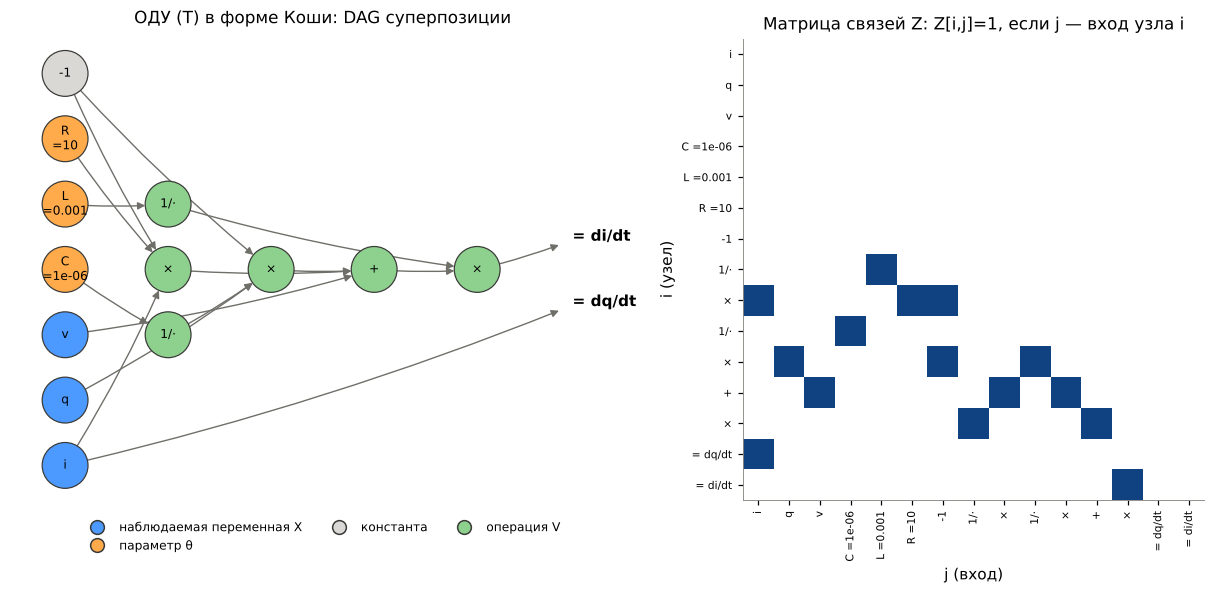

{'observed': 3, 'parameter': 3, 'constant': 1, 'operation': 6, 'output': 2, 'edges': 15, 'shared': 0}


In [8]:
ss_ = S.state_space()
q_, i_, v_ = ss_["symbols"]
dag_ode = ExpressionDAG.from_sympy({"dq/dt": ss_["dq/dt"], "di/dt": ss_["di/dt"]}, observed=[q_, i_, v_],
                                   parameters={S.R: 10.0, S.L: 1e-3, S.C: 1e-6})
fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw=dict(width_ratios=[1.35, 1]))
draw_dag(dag_ode, ax[0], title="ОДУ (T) в форме Коши: DAG суперпозиции")
draw_adjacency(dag_ode, ax[1], title="Матрица связей Z: Z[i,j]=1, если j — вход узла i")
savefig(fig, FIG / "dag_ode.png"); plt.show()
print(dag_ode.counts())

### 2.3 DAG частотной модели (J): $\operatorname{Re}Z_J$ и $\operatorname{Im}Z_J$ с общими подграфами

Оптимизатор работает с вещественными невязками, поэтому естественный вычислительный граф — пара выходов $(\operatorname{Re}Z,\operatorname{Im}Z)$ как функций $\omega$. Подвыражения $L\,\omega^{\beta}$ и $\omega^{-\alpha}/Q$ входят в оба выхода — это **общие узлы** (обведены розовым). Граф хранится тремя способами (словарь, позиционная матрица связей, `networkx`); каждое представление восстанавливает исходные выражения точно — это проверяется в тестах и ниже.

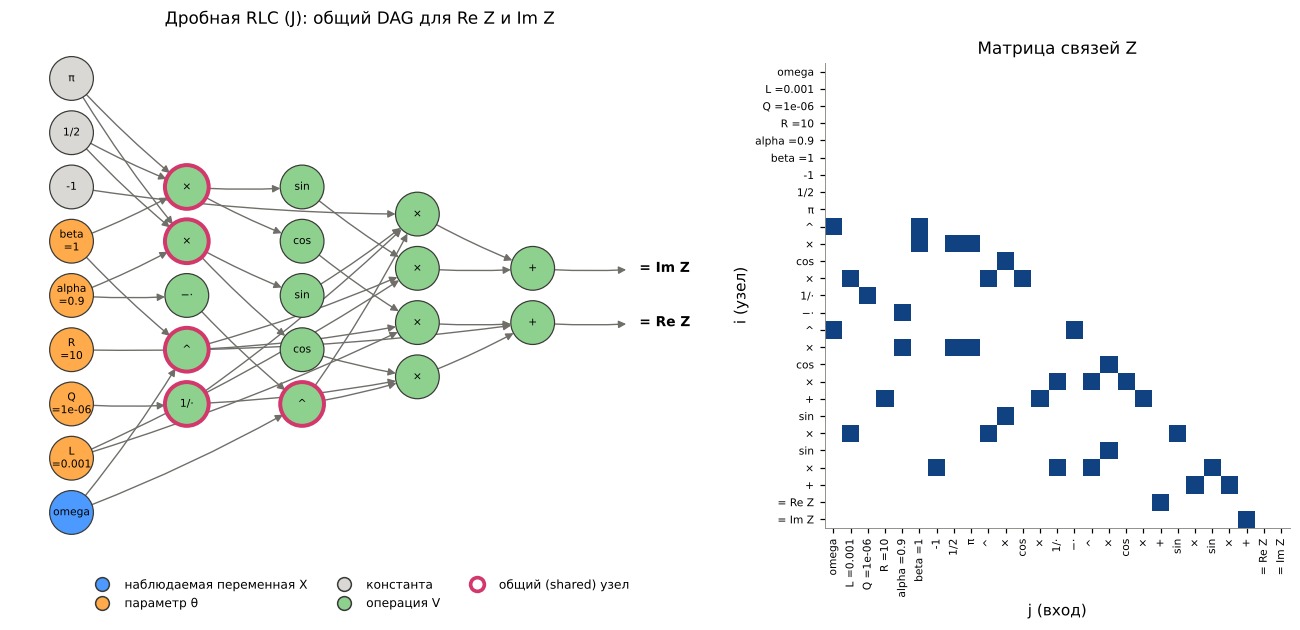

общие (shared) узлы: [(9, '^'), (10, '×'), (13, '1/·'), (15, '^'), (16, '×')]
словарь, первые узлы: {"0": {"kind": "observed", "label": "omega", "op": null, "args": [], "name": "omega"}, "1": {"kind": "parameter", "label": "L\n=0.001", "op": null, "args": [], "name": "L", "value": 0.001}, "2": {"kind": "parameter", "label": "Q\n=1e-06", "op": null, "args": [], "name": "Q", "value": 1e-06}}
последний операционный узел: {'kind': 'operation', 'label': '+', 'op': 'Add', 'args': [21, 23]}
восстановление из матрицы связей точно: True
интерпретатор графа vs модель: True


In [9]:
params_J = {S.R: 10.0, S.L: 1e-3, S.Q: 1e-6, S.alpha: 0.9, S.beta: 1.0}
dag_Z = ExpressionDAG.from_sympy({"Re Z": re_J, "Im Z": im_J}, observed=[S.omega], parameters=params_J)
fig, ax = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw=dict(width_ratios=[1.5, 1]))
draw_dag(dag_Z, ax[0], title="Дробная RLC (J): общий DAG для Re Z и Im Z", node_size=820, font_size=7)
draw_adjacency(dag_Z, ax[1])
savefig(fig, FIG / "dag_ZJ.png"); plt.show()

print("общие (shared) узлы:", [(n.id, n.label) for n in dag_Z.shared_nodes()])
d = dag_Z.to_dict()
print("словарь, первые узлы:", json.dumps({k: d[k] for k in list(d)[:3]}, ensure_ascii=False))
print("последний операционный узел:", d[len(d) - 3])
back = ExpressionDAG.from_adjacency(dag_Z.adjacency(), dag_Z.metadata()).to_sympy()
print("восстановление из матрицы связей точно:",
      sp.simplify(back["Re Z"] - re_J) == 0 and sp.simplify(back["Im Z"] - im_J) == 0)
w_ = np.logspace(2, 6, 5)
ev = dag_Z.evaluate({"omega": w_})
print("интерпретатор графа vs модель:", np.allclose(ev["Re Z"] + 1j * ev["Im Z"],
      models.series_rlc("J").predict([10.0, 1e-3, 1.0, 1e-6, 0.9], w_)))

### 2.4 Граф схемы

Второй, физический граф той же модели — граф электрической цепи: вершины — узлы цепи (1 — вход, ⊥ — земля), рёбра — элементы. Параллельные элементы — кратные рёбра. Цикломатическое число $E-V+1$ равно числу независимых контуров (и числу параллельных блоков). Узловой анализ на этом графе даёт тот же $Z(s)$, что и алгебра выражений (раздел 2.1).

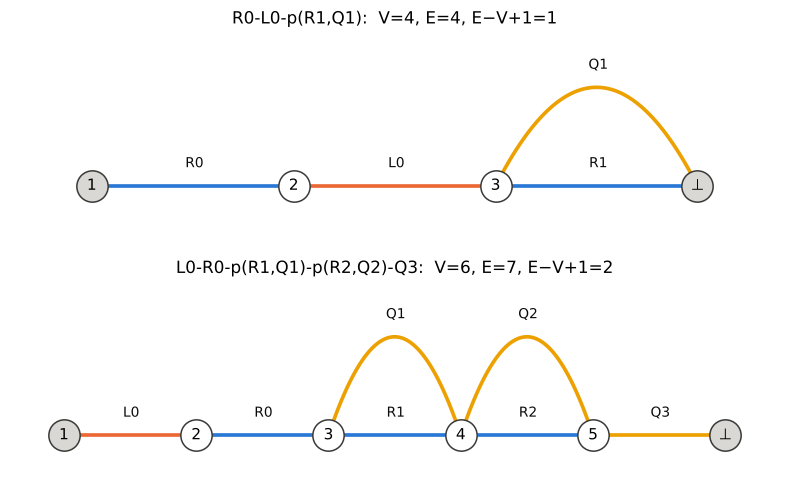

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5.4))
for a, m in zip(ax, [models.dummy_cell_model("J"), models.battery_model("J")]):
    G = circuit_graph(m.tree)
    draw_circuit_graph(G, a, title=f"{m.circuit}:  V={G.number_of_nodes()}, E={G.number_of_edges()}, "
                                    f"E−V+1={G.number_of_edges() - G.number_of_nodes() + 1}")
savefig(fig, FIG / "circuit_graphs.png"); plt.show()

## 3. Векторные поля $\mathbb R^3\to\mathbb R^3$

Вынужденная цепь (T) неавтономна. Добавив фазу источника $\varphi=\omega t$ как третью координату и перейдя к безразмерным переменным $\tau=\omega_0t$, $x=q/q_0$, $y=i/(\omega_0q_0)$, получаем автономное поле на $\mathbb R^2\times S^1$:
$$
F(x,y,\varphi)=\big(y,\;-x-2\zeta y+u\cos\varphi,\;\Omega\big),\qquad \zeta=\tfrac R2\sqrt{C/L},\ \ \Omega=\omega/\omega_0 .
$$
**Утверждение 7.** $\operatorname{div}F=-2\zeta$, $\operatorname{rot}F=(u\sin\varphi,\,0,\,-2)$; для любой измеримой области $A$ объём образа $\operatorname{vol}\Phi_\tau(A)=e^{-2\zeta\tau}\operatorname{vol}A$; мощность $\dot H=\nabla H\cdot F=-2\zeta y^2+uy\cos\varphi$ для энергии $H=(x^2+y^2)/2$.
*Доказательство.* Первые два равенства — прямое дифференцирование (SymPy ниже). По формуле Якоби $\tfrac{d}{d\tau}\det D\Phi_\tau=\operatorname{tr}\big(DF(\Phi_\tau)\big)\det D\Phi_\tau=\operatorname{div}F\cdot\det D\Phi_\tau$, откуда $\det D\Phi_\tau=e^{-2\zeta\tau}$ и, по замене переменных, утверждение об объёме. Последнее — скалярное произведение. ∎
Физический смысл: дивергенция — скорость диссипации ($-R/L$ в размерных переменных), $z$‑компонента ротора — вращение фазовой точки (колебания), скалярное произведение — баланс мощностей $P_{\rm source}-P_R$, векторное произведение $F\times\nabla H$ ортогонально траектории.

In [11]:
Fd = fields.driven_rlc_field()
x_, y_, ph_ = Fd.coords
H = (x_**2 + y_**2) / 2
gH = fields.gradient_field(H, Fd.coords)
print("F(x, y, φ) ="); display(Fd.components.T)
print("div F  =", Fd.divergence())
print("rot F  =", list(Fd.curl()))
print("DF     =", Fd.jacobian().tolist())
print("F·∇H   =", Fd.dot(gH))
print("F×∇H   =", list(Fd.cross(gH)))
print("div F (размерные переменные) =", fields.driven_rlc_field_dimensional().divergence())

zeta, u, Om = 0.15, 1.0, 1.2
Fn = fields.driven_rlc_field(zeta, u, Om)
grid = np.meshgrid(np.linspace(-2, 2, 21), np.linspace(-2, 2, 21), np.linspace(0, 2*np.pi, 41), indexing="ij")
print("конечные разности: max|div + 2ζ| =", np.abs(fields.fd_divergence(Fn.numeric(), grid) + 2*zeta).max())
for T_ in (1.0, 5.0):
    print(f"Лиувилль: det DΦ_{T_:.0f} = {Fn.flow_jacobian_det([0.5, 0.0, 0.0], T_):.10f},  "
          f"exp(-2ζτ) = {np.exp(-2*zeta*T_):.10f}")

F(x, y, φ) =


Matrix([[y, u*cos(varphi) - x - 2*y*zeta, Omega]])

div F  = -2*zeta
rot F  = [u*sin(varphi), 0, -2]
DF     = [[0, 1, 0], [-1, -2*zeta, -u*sin(varphi)], [0, 0, 0]]
F·∇H   = y*(u*cos(varphi) - 2*y*zeta)
F×∇H   = [-Omega*y, Omega*x, x*(-u*cos(varphi) + x + 2*y*zeta) + y**2]
div F (размерные переменные) = -R/L
конечные разности: max|div + 2ζ| = 2.55351295663786e-15
Лиувилль: det DΦ_1 = 0.7408182207,  exp(-2ζτ) = 0.7408182207
Лиувилль: det DΦ_5 = 0.2231301601,  exp(-2ζτ) = 0.2231301601


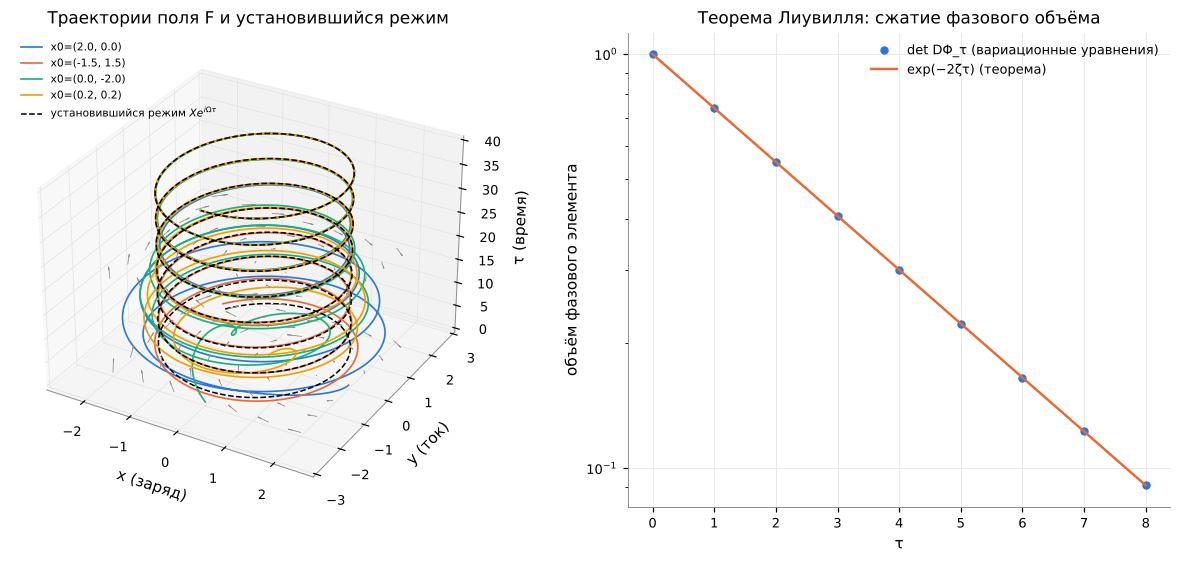

In [12]:
fig = plt.figure(figsize=(14, 5.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
tau_end = 40.0
for k, x0 in enumerate([(2.0, 0.0), (-1.5, 1.5), (0.0, -2.0), (0.2, 0.2)]):
    sol = Fn.trajectory([x0[0], x0[1], 0.0], (0.0, tau_end), n=2500)
    ax.plot(sol.y[0], sol.y[1], sol.t, color=PALETTE[k], lw=1.1, label=f"x0={x0}")
# предельный цикл (установившийся режим) из частотной характеристики
Zr = 2 * zeta * 1j * Om + 1 - Om**2               # (1 - Ω² + 2iζΩ) X = u
X = u / Zr
tt = np.linspace(0, tau_end, 800)
ax.plot((X * np.exp(1j * Om * tt)).real, (1j * Om * X * np.exp(1j * Om * tt)).real, tt, "k--", lw=1.0,
        label="установившийся режим $X e^{i\\Omega\\tau}$")
XX, YY = np.meshgrid(np.linspace(-2, 2, 7), np.linspace(-2, 2, 7))
for tz in (0.0, 20.0):
    U, V, Wc = Fn.numeric()(XX, YY, np.full_like(XX, Om * tz))
    ax.quiver(XX, YY, np.full_like(XX, tz), U, V, np.ones_like(XX) * 1.5, length=0.12, color="#8a8984", lw=0.5)
ax.set_xlabel("x (заряд)"); ax.set_ylabel("y (ток)"); ax.set_zlabel("τ (время)")
ax.set_title("Траектории поля F и установившийся режим")
ax.legend(loc="upper left", fontsize=7)
ax2 = fig.add_subplot(1, 2, 2)
taus = np.linspace(0, 8, 9)
dets = [Fn.flow_jacobian_det([0.5, 0.0, 0.0], T_) if T_ > 0 else 1.0 for T_ in taus]
ax2.semilogy(taus, dets, "o", color=PALETTE[0], label="det DΦ_τ (вариационные уравнения)")
ax2.semilogy(taus, np.exp(-2 * zeta * taus), "-", color=PALETTE[1], label="exp(−2ζτ) (теорема)")
ax2.set_xlabel("τ"); ax2.set_ylabel("объём фазового элемента"); ax2.legend()
ax2.set_title("Теорема Лиувилля: сжатие фазового объёма")
savefig(fig, FIG / "vector_field_3d.png"); plt.show()

## 4. Данные

Файлы скачиваются функцией `data.fetch_all()` по HTTPS с закреплённых коммитов (основной URL `raw.githubusercontent.com`, запасной — `github.com/.../raw/...`); каждый файл проверяется по SHA‑256, при совпадении используется кэш `data/raw/`.

**Особенность источника `zhang2020`.** В обработанных файлах статьи хранятся 60 значений $\operatorname{Re}Z$ и 60 значений $-\operatorname{Im}Z$ без частот. В статье указано «60 частот от 0,02 Гц до 20 кГц». Сетку восстанавливаем как логарифмическую с включёнными концами $f_k=2\cdot10^4\cdot10^{-6k/59}$; частоты 115,778; 17,80; 11,145; 2,16; 0,165 Гц, приводимые в статье и последующих работах, попадают на узлы $k=22,30,32,39,50$ с точностью до округления (тест `test_zhang_frequency_grid_matches_published_values`). Это **явное допущение**; относительная ошибка частоты $\varepsilon$ масштабирует оценки $L$, $C$, $Q$ не более чем на $\sim\varepsilon$ и не влияет на $R$ и $\alpha$.

In [13]:
paths = data.fetch_all(verbose=False)
for name, p in paths.items():
    print(f"{name:34s} {p.stat().st_size:>9d} B  sha256 {data.sha256(p)[:16]}…  ok")

bat = data.load_battery_series()
circuits = data.load_test_circuits()
li_example = data.load_example_battery()
res_data = {mm: data.load_resonator(mm) for mm in (36, 72, 144)}
print()
print(f"zhang2020: {bat.Z.shape[0]} спектров × {bat.Z.shape[1]} частот, циклы {bat.cycles[0]}…{bat.cycles[-1]}, "
      f"ёмкость {bat.capacity[0]:.2f} → {bat.capacity[-1]:.2f} мА·ч")
for c in circuits:
    print(f"{c.name}: {len(c.freq)} точек, {c.freq.min():.0f}…{c.freq.max():.0f} Гц, регистрация {c.time.max():.0f} с")
for mm, d in res_data.items():
    print(f"резонатор {mm:3d} мм: {len(d.freq)} точек, {d.freq[0]/1e9:.0f}…{d.freq[-1]/1e9:.0f} ГГц, Z0 = {d.z0} Ом")

zhang2020_Code-Matlab.zip            3666132 B  sha256 7d6ab9b3d48a2ead…  ok
impedancepy_Circuit1_EIS_1.z            8195 B  sha256 00c920ac9224ddee…  ok
impedancepy_Circuit1_EIS_2.z            8195 B  sha256 aefc7bfa3c892535…  ok
impedancepy_Circuit2_EIS_1.z            8882 B  sha256 2bb61593f88bc5cf…  ok
impedancepy_Circuit2_EIS_2.z            8881 B  sha256 351507e00a4d322e…  ok
impedancepy_Circuit3_EIS_1.z            8628 B  sha256 3324a5ce6e9abb35…  ok
impedancepy_Circuit3_EIS_2.z            8628 B  sha256 93731fc0606c3038…  ok
impedancepy_exampleData.csv             5007 B  sha256 7a6185b5e95e7457…  ok
skrf_resonator_36mm.s2p                73108 B  sha256 9fd37c4871cc79aa…  ok
skrf_resonator_72mm.s2p               728393 B  sha256 7d28c2928d7d0e7e…  ok
skrf_resonator_144mm.s2p              727479 B  sha256 fefeda1edca5643e…  ok

zhang2020: 299 спектров × 60 частот, циклы 2…598, ёмкость 40.47 → 27.54 мА·ч
Circuit1_EIS_1: 48 точек, 1…50000 Гц, регистрация 41 с
Circuit1_EIS_2: 48 т

### 4.1 Данные в 3D с учётом времени

* **Li‑ion элемент:** годограф Найквиста $(Z',-Z'')$ для каждого второго цикла; третья ось — номер цикла (медленное время старения). Видны: индуктивный хвост ($-Z''<0$ на высоких частотах), омическое сопротивление, две сжатые дуги и диффузионная ветвь на низких частотах; с ростом числа циклов дуги растут.
* **Тестовые цепи:** третья ось — время регистрации точки прибором (с): развёртка начинается с высоких частот, низкочастотные точки снимаются дольше.
* **Резонатор 144 мм:** $(\operatorname{Re}S_{21},\operatorname{Im}S_{21})$ как функция частоты — каждая мода даёт окружность (годограф резонансного контура), соединённые фоновой утечкой. Частота здесь играет роль «времени» развёртки анализатора.

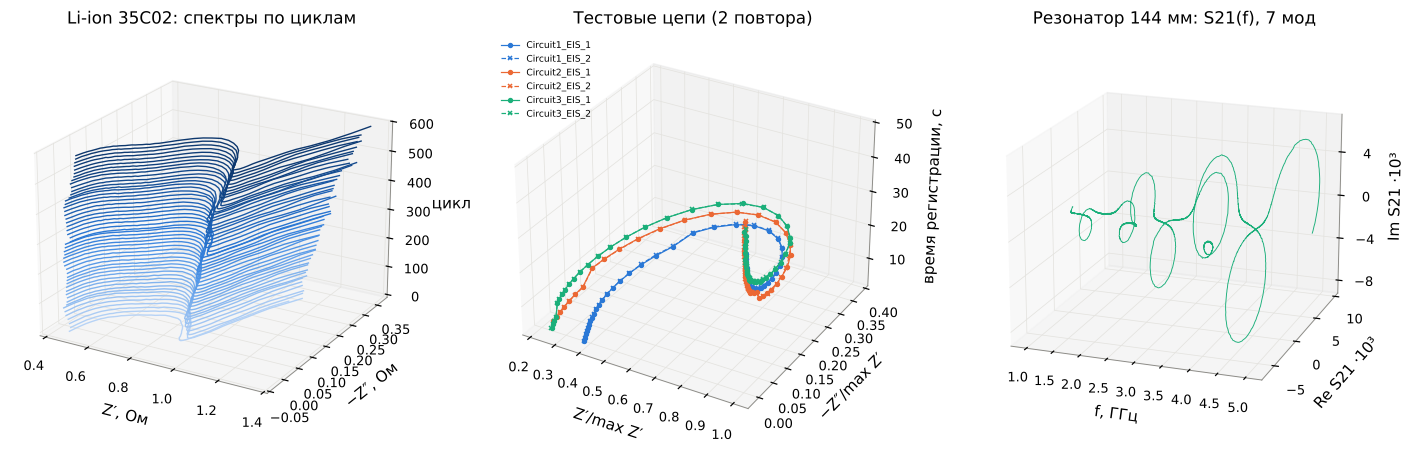

In [14]:
fig = plt.figure(figsize=(16, 5.2))
ax = fig.add_subplot(1, 3, 1, projection="3d")
sel = np.arange(0, len(bat.cycles), 6)
for j in sel:
    ax.plot(bat.Z[j].real, -bat.Z[j].imag, np.full(60, bat.cycles[j]), color=BLUES(j / len(bat.cycles)), lw=0.9)
ax.set_xlabel("Z′, Ом"); ax.set_ylabel("−Z″, Ом"); ax.set_zlabel("цикл")
ax.set_title("Li-ion 35C02: спектры по циклам"); ax.view_init(22, -60)

ax = fig.add_subplot(1, 3, 2, projection="3d")
for k, c in enumerate(circuits):
    zn = c.Z / (c.Z.real.max())                 # нормировка: три цепи в одном масштабе
    ax.plot(zn.real, -zn.imag, c.time, "o-" if c.meta["replicate"] == 1 else "x--", ms=2.5, lw=0.8,
            color=PALETTE[c.meta["circuit"] - 1], label=c.name)
ax.set_xlabel("Z′/max Z′"); ax.set_ylabel("−Z″/max Z′"); ax.set_zlabel("время регистрации, с")
ax.set_title("Тестовые цепи (2 повтора)"); ax.legend(fontsize=6, loc="upper left")

ax = fig.add_subplot(1, 3, 3, projection="3d")
d = res_data[144]
ax.plot(d.freq / 1e9, d.s21.real * 1e3, d.s21.imag * 1e3, lw=0.6, color=PALETTE[2])
ax.set_xlabel("f, ГГц"); ax.set_ylabel("Re S21 ·10³"); ax.set_zlabel("Im S21 ·10³")
ax.set_title("Резонатор 144 мм: S21(f), 7 мод"); ax.view_init(18, -70)
from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(4)); ax.zaxis.set_major_locator(MaxNLocator(5))
savefig(fig, FIG / "data_3d.png"); plt.show()

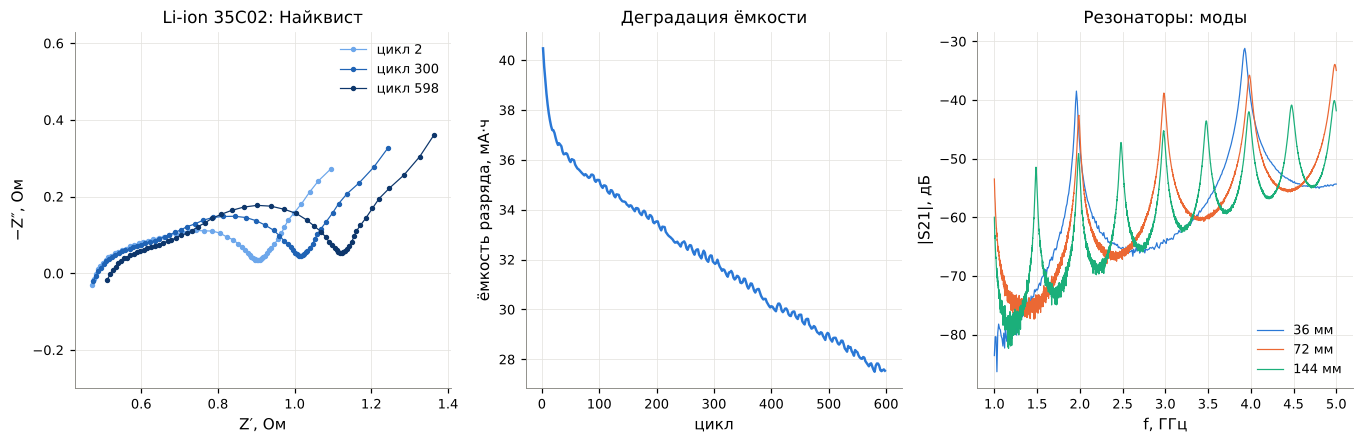

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for j in (0, 149, 298):
    nyquist(ax[0], bat.Z[j], "o-", ms=2.5, lw=0.8, label=f"цикл {bat.cycles[j]}", color=BLUES(0.25 + 0.75 * j / 298))
ax[0].set_title("Li-ion 35C02: Найквист"); ax[0].legend()
ax[1].plot(bat.cycles, bat.capacity, color=PALETTE[0])
ax[1].set_xlabel("цикл"); ax[1].set_ylabel("ёмкость разряда, мА·ч"); ax[1].set_title("Деградация ёмкости")
for k, mm in enumerate((36, 72, 144)):
    d = res_data[mm]
    ax[2].plot(d.freq / 1e9, 20 * np.log10(np.abs(d.s21)), lw=0.8, color=PALETTE[k], label=f"{mm} мм")
ax[2].set_xlabel("f, ГГц"); ax[2].set_ylabel("|S21|, дБ"); ax[2].set_title("Резонаторы: моды"); ax[2].legend()
savefig(fig, FIG / "data_overview.png"); plt.show()

## 5. Вектор параметров, оптимизатор и солвер

### 5.1 Вектор параметров $\boldsymbol\theta$ и ожидаемые значения

Каждая модель хранит параметры в векторе $\boldsymbol\theta$ с описанием (`ParameterSpec`): ожидаемое значение (априорный порядок величины, он же начальная точка локального поиска), допустимые границы, единицы и преобразование во внутренние неограниченные координаты $u$ (`log` для положительных величин, `logit` для показателей $\alpha,\beta\in(\cdot,1]$). Ожидаемые значения: тестовая цепь — сотни ом и десятки нанофарад, паразитная индуктивность ~1 мкГн; Li‑ion элемент 45 мА·ч — $R_0\approx0{,}5$ Ом, дуги по десятым долям ома, $\alpha$ около 0,6–0,9; резонатор — $Q\sim 50$, $\alpha\approx 0{,}98$ (что соответствует $\tan\delta\approx0{,}03$).

In [16]:
MODELS = {
    "circuit-T": models.dummy_cell_model("T"), "circuit-J": models.dummy_cell_model("J"),
    "circuit-J+": models.dummy_cell_model("J+"),
    "battery-T": models.battery_model("T"), "battery-J": models.battery_model("J"),
    "resonator-T": models.resonator_model("T"), "resonator-J": models.resonator_model("J"),
}
for key in ("circuit-J", "battery-J", "resonator-J"):
    print(f"{key}: θ = ({', '.join(MODELS[key].names)}),  dim θ = {MODELS[key].k}")
    display(MODELS[key].table()[["expected", "lower", "upper", "transform", "unit", "description"]])

circuit-J: θ = (R0, L0, R1, Q1, alpha1),  dim θ = 5


,expected,lower,upper,transform,unit,description
parameter,,,,,,
R0,1.0000e+02,1.0000e-02,100000.00,log,Ω,resistance
L0,1.0000e-06,1.0000e-10,0.01,log,H,lead inductance
R1,5.0000e+02,1.0000e-02,1000000.00,log,Ω,resistance
Q1,1.0000e-07,1.0000e-13,0.01,log,F·s^(α−1),CPE pseudo-capacitance
alpha1,9.9000e-01,8.0000e-01,1.00,logit,—,CPE exponent (α = 1: ideal capacitor)


battery-J: θ = (L0, R0, R1, Q1, alpha1, R2, Q2, alpha2, Q3, alpha3),  dim θ = 10


,expected,lower,upper,transform,unit,description
parameter,,,,,,
L0,3.0000e-07,1.0000e-10,0.0001,log,H,inductance
R0,5.0000e-01,1.0000e-03,5.0000,log,Ω,resistance
R1,2.0000e-01,1.0000e-04,5.0000,log,Ω,resistance
Q1,3.0000e-02,1.0000e-07,100.0000,log,F·s^(α−1),CPE pseudo-capacitance
alpha1,6.0000e-01,3.0000e-01,1.0000,logit,—,CPE exponent (α = 1: ideal capacitor)
R2,2.0000e-01,1.0000e-04,5.0000,log,Ω,resistance
Q2,3.0000e-02,1.0000e-06,100.0000,log,F·s^(α−1),CPE pseudo-capacitance
alpha2,9.0000e-01,3.0000e-01,1.0000,logit,—,CPE exponent (α = 1: ideal capacitor)
Q3,1.0000e+01,1.0000e-03,100000.0000,log,F·s^(α−1),CPE pseudo-capacitance


resonator-J: θ = (f_r, alpha, g_re, g_im, d_re, d_im),  dim θ = 6


,expected,lower,upper,transform,unit,description
parameter,,,,,,
f_r,2.0000e+09,1.9000e+09,2.1000e+09,lin,Hz,resonance frequency
alpha,9.8000e-01,8.0000e-01,1.0000e+00,logit,—,CPE exponent of the mode capacitance
g_re,0.0000e+00,-1.0000e+00,1.0000e+00,lin,—,peak transmission (real part)
g_im,0.0000e+00,-1.0000e+00,1.0000e+00,lin,—,peak transmission (imag. part)
d_re,0.0000e+00,-1.0000e+00,1.0000e+00,lin,—,leakage (real part)
d_im,0.0000e+00,-1.0000e+00,1.0000e+00,lin,—,leakage (imag. part)


### 5.2 Функция ошибки и выбор оптимизатора

Невязка $r_k(\boldsymbol\theta)=w_k\big(\hat Z_k(\boldsymbol\theta)-Z_k\big)$, $w_k=1/|Z_k|$; минимизируем $S(\boldsymbol\theta)=\sum_k\big[(\operatorname{Re}r_k)^2+(\operatorname{Im}r_k)^2\big]$ ($n=2N$ вещественных невязок). **Допущение:** $Z_k=\hat Z_k(\boldsymbol\theta^*)+\varepsilon_k$ с независимыми круговыми гауссовыми ошибками, $\sigma_k\propto|Z_k|$; тогда $\hat{\boldsymbol\theta}=\arg\min S$ — оценка максимального правдоподобия, а $\operatorname{Cov}\hat{\boldsymbol\theta}\approx\hat\sigma^2(J^{\mathsf T}J)^{+}$, $\hat\sigma^2=S/(n-k)$ (аппроксимация Лапласа; калибровка проверена тестом `test_recover_fractional_dummy_model_and_coverage`).
$\mathrm{AIC}=n\ln(S/n)+2k$, $\mathrm{BIC}=n\ln(S/n)+k\ln n$.

Кандидаты: **TRF** (доверительная область типа Левенберга–Марквардта, SciPy) и **LM** (MINPACK) с аналитическим якобианом из SymPy; **multistart** TRF из точек латинского гиперкуба; **дифференциальная эволюция** (DE) и **CMA‑ES** — глобальные, с доводкой TRF. Сравнение на первом спектре Li‑ion элемента (самая трудная задача: 10 параметров):

In [17]:
w_b = bat.omega
opt_tables = {}
for key in ("battery-T", "battery-J"):
    tab, _ = fitting.compare_optimizers(MODELS[key], w_b, bat.Z[0], methods=("trf", "lm", "multistart", "de", "cmaes"),
                                        seed=SEED)
    opt_tables[key] = tab
    print(key)
    display(tab[["S", "rmse", "nfev", "seconds"]])

battery-T


,S,rmse,nfev,seconds
method,,,,
trf,0.141,0.0343,34,0.0386
lm,0.141,0.0343,34,0.0076
multistart,0.141,0.0343,852,0.3429
de,0.141,0.0343,57858,7.0213
cmaes,0.141,0.0343,3098,0.5815


battery-J


,S,rmse,nfev,seconds
method,,,,
trf,0.0005,0.002,34,0.0591
lm,0.0005,0.002,35,0.0144
multistart,0.0005,0.002,2904,2.0407
de,0.0005,0.002,102684,15.2885
cmaes,0.0005,0.002,15484,3.6001


Все пять методов приходят в один и тот же минимум (одинаковые $S$ до 4–5 знаков), но цена различается на 3–4 порядка: TRF/LM с символьным якобианом — десятки вычислений модели, DE — десятки тысяч. **Выбор:** глобальный поиск (DE, `seed=0`) для первой точки каждой задачи и для контроля, затем TRF с аналитическим якобианом; для последовательности 299 спектров — продолжение по параметру (тёплый старт от предыдущего цикла) с контрольными глобальными перезапусками.

### 5.3 Выбор солвера (временная область)

Для учебной модели сравниваем методы `solve_ivp` с точным решением при скачке напряжения ($R=10$ Ом, $L=1$ мГн, $C=1$ мкФ, $\zeta\approx0{,}16$). Для дробной модели — схема Грюнвальда–Летникова (порядок 1) и обратное преобразование Лапласа по контуру Талбота (`mpmath`), которое работает для любой схемы из DSL.

In [18]:
R_, L_, C_, V0 = 10.0, 1e-3, 1e-6, 1.0
t_ = np.linspace(0, 2e-3, 2001)
exact = td.analytic_series_rlc_step(R_, L_, C_, V0, t_)
rows = []
for meth in ["RK45", "DOP853", "Radau", "BDF", "LSODA"]:
    t0 = time.perf_counter(); sol = td.ode_series_rlc(R_, L_, C_, lambda tt: V0, t_, method=meth)
    rows.append(dict(солвер=meth, класс="неявный" if meth in ("Radau", "BDF") else ("авто" if meth == "LSODA" else "явный"),
                     max_abs_err=np.abs(sol.y[1] - exact).max(), nfev=sol.nfev, ms=1e3 * (time.perf_counter() - t0)))
for n in (1001, 4001, 16001):
    tg = np.linspace(0, 2e-3, n)
    t0 = time.perf_counter(); g = td.gl_series_rlc(R_, L_, C_, lambda x: np.where(x > 0, V0, 0.0), tg)
    rows.append(dict(солвер=f"GL, N={n}", класс="дробный, O(h)", nfev=n,
                     max_abs_err=np.abs(g["i"] - td.analytic_series_rlc_step(R_, L_, C_, V0, tg)).max(),
                     ms=1e3 * (time.perf_counter() - t0)))
mser = models.series_rlc("T")
tt_ = np.array([2e-4, 1e-3, 2e-3])
t0 = time.perf_counter(); vt = td.step_voltage(mser, [R_, L_, C_], tt_)
rows.append(dict(солвер="Talbot (mpmath)", класс="обратный Лаплас", nfev=len(tt_),
                 max_abs_err=np.abs(vt - (R_ + tt_ / C_)).max(), ms=1e3 * (time.perf_counter() - t0)))
solver_table = pd.DataFrame(rows).set_index("солвер")
solver_table

,класс,max_abs_err,nfev,ms
солвер,,,,
RK45,явный,5.1337e-10,3248,54.1718
DOP853,явный,5.7232e-10,1682,21.3427
Radau,неявный,3.2477e-11,10665,448.0280
BDF,неявный,8.6460e-09,2379,189.7086
LSODA,авто,6.5292e-09,1668,35.8959
"GL, N=1001","дробный, O(h)",2.0750e-03,1001,3.7104
"GL, N=4001","дробный, O(h)",5.6121e-04,4001,18.3026
"GL, N=16001","дробный, O(h)",1.4349e-04,16001,241.6953
Talbot (mpmath),обратный Лаплас,2.2737e-13,3,40.0477


**Выбор солвера.** Для учебной ОДУ все методы дают ошибку $\lesssim10^{-8}$ А при `rtol=1e-8`; задачи эквивалентных схем батареи жёсткие (постоянные времени от $10^{-5}$ до $10^{3}$ с), поэтому для целого порядка выбираем **LSODA** (автоматическое переключение на неявный BDF, наименьшее число вычислений). Для дробного порядка: **GL** — для сравнения с ОДУ и проверки «время → частота» (сходимость $O(h)$: ошибка падает в ~4 раза при уменьшении шага в 4 раза), **Талбот** — для многомасштабных откликов батареи (точность ~$10^{-12}$, не требует равномерной сетки по времени).

## 6. Подгонка параметров

### 6.1 Тестовые цепи из дискретных компонентов (источник `impedancepy`)

Три модели на каждом из шести спектров: T `R0-L0-p(R1,C1)`, J `R0-L0-p(R1,Q1)`, J+ `R0-Lf0-p(R1,Q1)`. Оптимизатор — DE + TRF.

In [19]:
fits_c = {}
rows = []
for c in circuits:
    for kind in ("T", "J", "J+"):
        m = MODELS[f"circuit-{kind}"]
        r = fitting.fit(m, c.omega, c.Z, method="de", seed=SEED)
        fits_c[(c.name, kind)] = r
        row = dict(spectrum=c.name, model=kind, rmse=r.rmse, BIC=r.bic, cond=r.cond)
        row.update({k: v for k, v in r.params.items()})
        row.update({f"se_{k}": v for k, v in zip(r.names, r.stderr)})
        rows.append(row)
circ_table = pd.DataFrame(rows)
circ_table.to_csv(RES / "fits_test_circuits.csv", index=False)
show = circ_table.pivot(index="spectrum", columns="model", values=["rmse", "BIC"])
show["ΔBIC(J−T)"] = show[("BIC", "J")] - show[("BIC", "T")]
show["ΔBIC(J+−J)"] = show[("BIC", "J+")] - show[("BIC", "J")]
display(show)
display(circ_table[circ_table.model == "J"].set_index("spectrum")[["R0", "L0", "R1", "Q1", "alpha1", "se_alpha1"]])

rmse                  ...        BIC ΔBIC(J−T) ΔBIC(J+−J)
model                J      J+       T  ...          T                     
spectrum                                ...                                
Circuit1_EIS_1  0.0004  0.0004  0.0007  ... -1367.2494 -110.3452     4.5643
Circuit1_EIS_2  0.0004  0.0004  0.0007  ... -1372.4115 -101.1730     4.5643
Circuit2_EIS_1  0.0019  0.0019  0.0025  ... -1323.1869  -55.9440     4.7185
Circuit2_EIS_2  0.0020  0.0020  0.0025  ... -1322.1207  -50.1518     4.7185
Circuit3_EIS_1  0.0010  0.0010  0.0014  ... -1381.2867  -51.3440     4.6634
Circuit3_EIS_2  0.0011  0.0011  0.0015  ... -1358.4509  -57.4540     4.6634

[6 rows x 8 columns]

,R0,L0,R1,Q1,alpha1,se_alpha1
spectrum,,,,,,
Circuit1_EIS_1,29.0949,3.0221e-06,46.7269,1.0636e-05,0.9970,0.0002
Circuit1_EIS_2,29.0805,2.9855e-06,46.7262,1.0625e-05,0.9972,0.0002
Circuit2_EIS_1,148.6116,3.3332e-06,504.5000,3.3125e-08,0.9937,0.0007
Circuit2_EIS_2,148.6744,3.2940e-06,504.2778,3.3053e-08,0.9939,0.0007
Circuit3_EIS_1,1500.2969,6.9379e-05,4639.4015,2.0704e-08,0.9969,0.0004
Circuit3_EIS_2,1499.8033,6.9990e-05,4640.2392,2.0802e-08,0.9964,0.0004


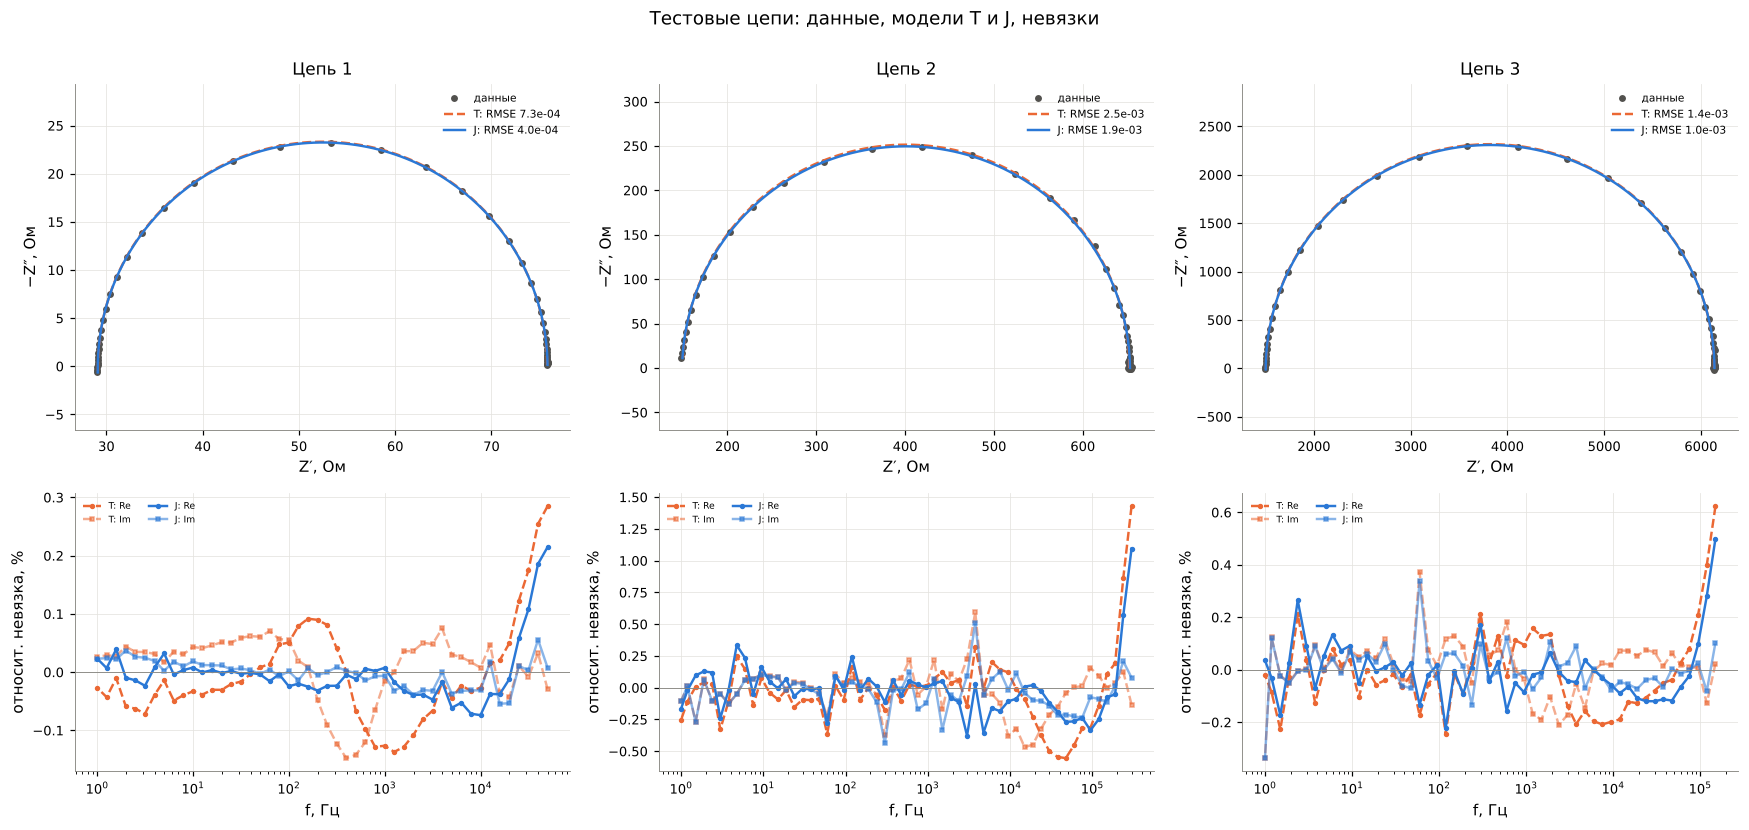

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5), gridspec_kw=dict(height_ratios=[1.25, 1]))
for k, cid in enumerate((1, 2, 3)):
    c = next(s for s in circuits if s.name == f"Circuit{cid}_EIS_1")
    wf = 2 * np.pi * np.logspace(np.log10(c.freq.min()), np.log10(c.freq.max()), 400)
    nyquist(ax[0, k], c.Z, "o", ms=3.5, color="#52514e", label="данные")
    for kind, ls, col in (("T", "--", PALETTE[1]), ("J", "-", PALETTE[0])):
        r = fits_c[(c.name, kind)]
        zf = MODELS[f"circuit-{kind}"].predict(r.theta, wf)
        ax[0, k].plot(zf.real, -zf.imag, ls, color=col, lw=1.6, label=f"{kind}: RMSE {r.rmse:.1e}")
        zr = MODELS[f"circuit-{kind}"].predict(r.theta, c.omega)
        rel = (zr - c.Z) / np.abs(c.Z)
        ax[1, k].semilogx(c.freq, 100 * rel.real, ls, marker="o", ms=2.5, color=col, label=f"{kind}: Re")
        ax[1, k].semilogx(c.freq, 100 * rel.imag, ls, marker="s", ms=2.5, color=col, alpha=0.55, label=f"{kind}: Im")
    ax[0, k].set_title(f"Цепь {cid}"); ax[0, k].legend(fontsize=7)
    ax[1, k].axhline(0, color="#8a8984", lw=0.6)
    ax[1, k].set_xlabel("f, Гц"); ax[1, k].set_ylabel("относит. невязка, %"); ax[1, k].legend(fontsize=6, ncol=2)
fig.suptitle("Тестовые цепи: данные, модели T и J, невязки", y=1.0)
fig.tight_layout(); savefig(fig, FIG / "fit_test_circuits.png"); plt.show()

**Наблюдения.** (1) Обе модели описывают данные с относительной ошибкой $10^{-3}$, но невязки модели T имеют систематическую «волну» по частоте, а у J они в основном случайны; $\Delta\mathrm{BIC}(J-T)$ от −50 до −110 — сильное свидетельство в пользу CPE. При этом $\hat\alpha_1=0{,}994\ldots0{,}997$: отклонение от идеального конденсатора мало (0,3–0,6 %), но статистически надёжно ($1-\hat\alpha$ составляет 8–15 стандартных ошибок) — это в точности эффект диэлектрической абсорбции, описанный Westerlund & Ekstam. Гипотеза H1 подтверждается в слабой форме: учебная модель адекватна на уровне 0,1–0,3 %, но не на уровне шума прибора. (2) Дробная катушка не нужна: $\hat\beta\to1$, $\Delta\mathrm{BIC}(J+-J)\approx+5$ (штраф за лишний параметр). (3) Повторы согласуются: оценки $R_0,R_1,Q_1,\alpha_1$ двух повторов совпадают в пределах долей процента. (4) На самых высоких частотах ($f\gtrsim 5\cdot10^4$ Гц) у **обеих** моделей остаётся систематическая невязка 0,3–1,4 % — её не объясняет ни CPE, ни $L_0$; это ошибка модели наблюдения (тракт прибора), а не цепи. (5) Для цепей 1–2 $\hat L_0\approx3$ мкГн — правдоподобная индуктивность выводов; для высокоомной цепи 3 $\hat L_0\approx70$ мкГн — это не физическая индуктивность, а фазовая погрешность потенциостата на высоких частотах в диапазоне больших сопротивлений (ради её обнаружения цепи и собирались). Это пример того, как параметр «впитывает» ошибку модели наблюдения — кандидат для лабораторной 3 (возмущение модели).

### 6.2 Литий‑ионный элемент: 299 спектров (источник `zhang2020`)

Сначала первый спектр (цикл 2) — глобальная оптимизация обеих моделей; затем отслеживание параметров по всем циклам с тёплым стартом и контрольными DE‑перезапусками каждые 50 спектров.

T: RMSE = 0.0343, BIC = -776.0, cond = 4.5e+00


,L0,R0,R1,C1,R2,C2,C3
estimate,2.0623e-07,0.4954,0.1650,0.0011,0.2690,0.0182,23.5914
stderr,8.5642e-08,0.0054,0.0098,0.0001,0.0105,0.0020,1.6251
rel_stderr_%,4.1527e+01,1.0930,5.9630,11.2181,3.9038,10.8227,6.8885


J: RMSE = 0.0020, BIC = -1448.3, cond = 2.0e+02


,L0,R0,R1,Q1,alpha1,R2,Q2,alpha2,Q3,alpha3
estimate,4.6259e-07,0.4413,0.288,0.0420,0.5301,0.1706,0.0385,0.8992,10.9001,0.6239
stderr,8.0311e-09,0.0025,0.020,0.0061,0.0166,0.0162,0.0013,0.0235,0.1309,0.0044
rel_stderr_%,1.7361e+00,0.5760,6.938,14.5533,3.1287,9.5115,3.4851,2.6160,1.2012,0.7066


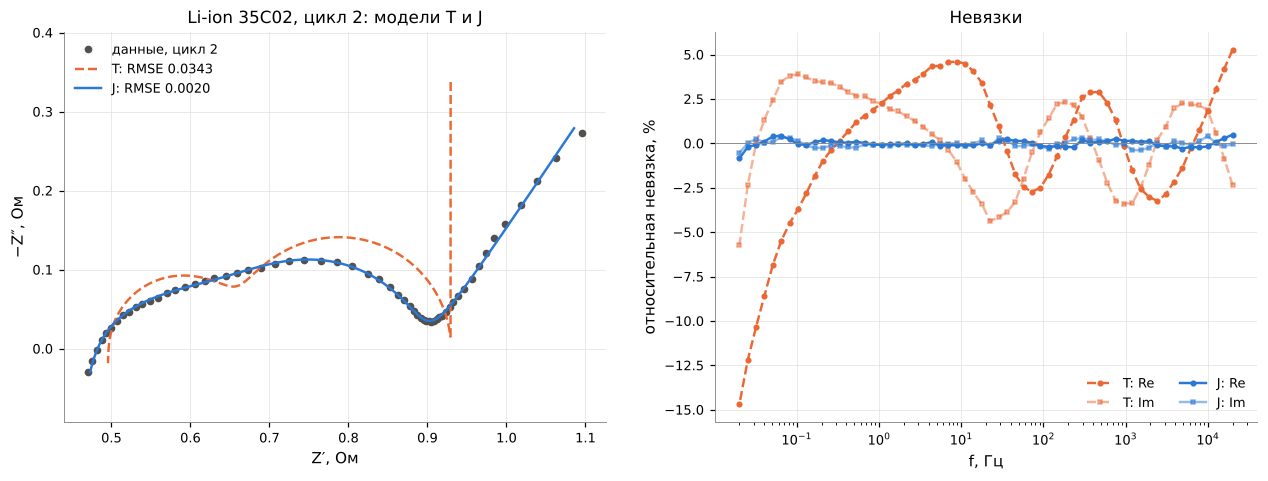

In [21]:
mBT, mBJ = MODELS["battery-T"], MODELS["battery-J"]
r0 = {k: fitting.fit(MODELS[f"battery-{k}"], w_b, bat.Z[0], method="de", seed=SEED) for k in ("T", "J")}
for k, r in r0.items():
    print(f"{k}: RMSE = {r.rmse:.4f}, BIC = {r.bic:.1f}, cond = {r.cond:.1e}")
    display(r.table().T)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
wf = 2 * np.pi * np.logspace(np.log10(0.02), np.log10(2e4), 500)
nyquist(ax[0], bat.Z[0], "o", ms=4, color="#52514e", label="данные, цикл 2")
for k, ls, col in (("T", "--", PALETTE[1]), ("J", "-", PALETTE[0])):
    zf = MODELS[f"battery-{k}"].predict(r0[k].theta, wf)
    ax[0].plot(zf.real, -zf.imag, ls, color=col, label=f"{k}: RMSE {r0[k].rmse:.4f}")
    rel = (MODELS[f"battery-{k}"].predict(r0[k].theta, w_b) - bat.Z[0]) / np.abs(bat.Z[0])
    ax[1].semilogx(bat.freq, 100 * rel.real, ls, marker="o", ms=3, color=col, label=f"{k}: Re")
    ax[1].semilogx(bat.freq, 100 * rel.imag, ls, marker="s", ms=3, color=col, alpha=0.5, label=f"{k}: Im")
ax[0].legend(); ax[0].set_title("Li-ion 35C02, цикл 2: модели T и J")
ax[1].axhline(0, color="#8a8984", lw=0.6); ax[1].legend(ncol=2)
ax[1].set_xlabel("f, Гц"); ax[1].set_ylabel("относительная невязка, %"); ax[1].set_title("Невязки")
savefig(fig, FIG / "fit_battery_cycle2.png"); plt.show()

In [22]:
t0 = time.perf_counter()
checks = {k: [] for k in ("T", "J")}
track = {k: fitting.track(MODELS[f"battery-{k}"], w_b, bat.Z, r0[k].theta, refit_every=50, refit_method="de",
                          checks=checks[k]) for k in ("T", "J")}
print(f"отслеживание 2 × 299 спектров: {time.perf_counter() - t0:.1f} с")
for k in ("T", "J"):
    gain = [(c["S_warm"] - c["S_global"]) / c["S_warm"] for c in checks[k]]
    print(f"{k}: контрольных DE-перезапусков {len(gain)}, максимальное относительное уменьшение S "
          f"глобальным поиском {max(gain):.1e}")
TH = {k: np.array([r.theta for r in v]) for k, v in track.items()}
SE = {k: np.array([r.stderr for r in v]) for k, v in track.items()}
RM = {k: np.array([r.rmse for r in v]) for k, v in track.items()}
for k in ("T", "J"):
    df = pd.DataFrame(TH[k], columns=MODELS[f"battery-{k}"].names)
    df.insert(0, "cycle", bat.cycles); df["rmse"] = RM[k]; df["capacity_mAh"] = bat.capacity
    df.to_csv(RES / f"battery_track_{k}.csv", index=False)
    print(f"{k}: RMSE медиана {np.median(RM[k]):.4f}, максимум {RM[k].max():.4f}")

отслеживание 2 × 299 спектров: 134.8 с
T: контрольных DE-перезапусков 6, максимальное относительное уменьшение S глобальным поиском 6.3e-13
J: контрольных DE-перезапусков 6, максимальное относительное уменьшение S глобальным поиском 1.9e-13
T: RMSE медиана 0.0359, максимум 0.0369
J: RMSE медиана 0.0034, максимум 0.0048


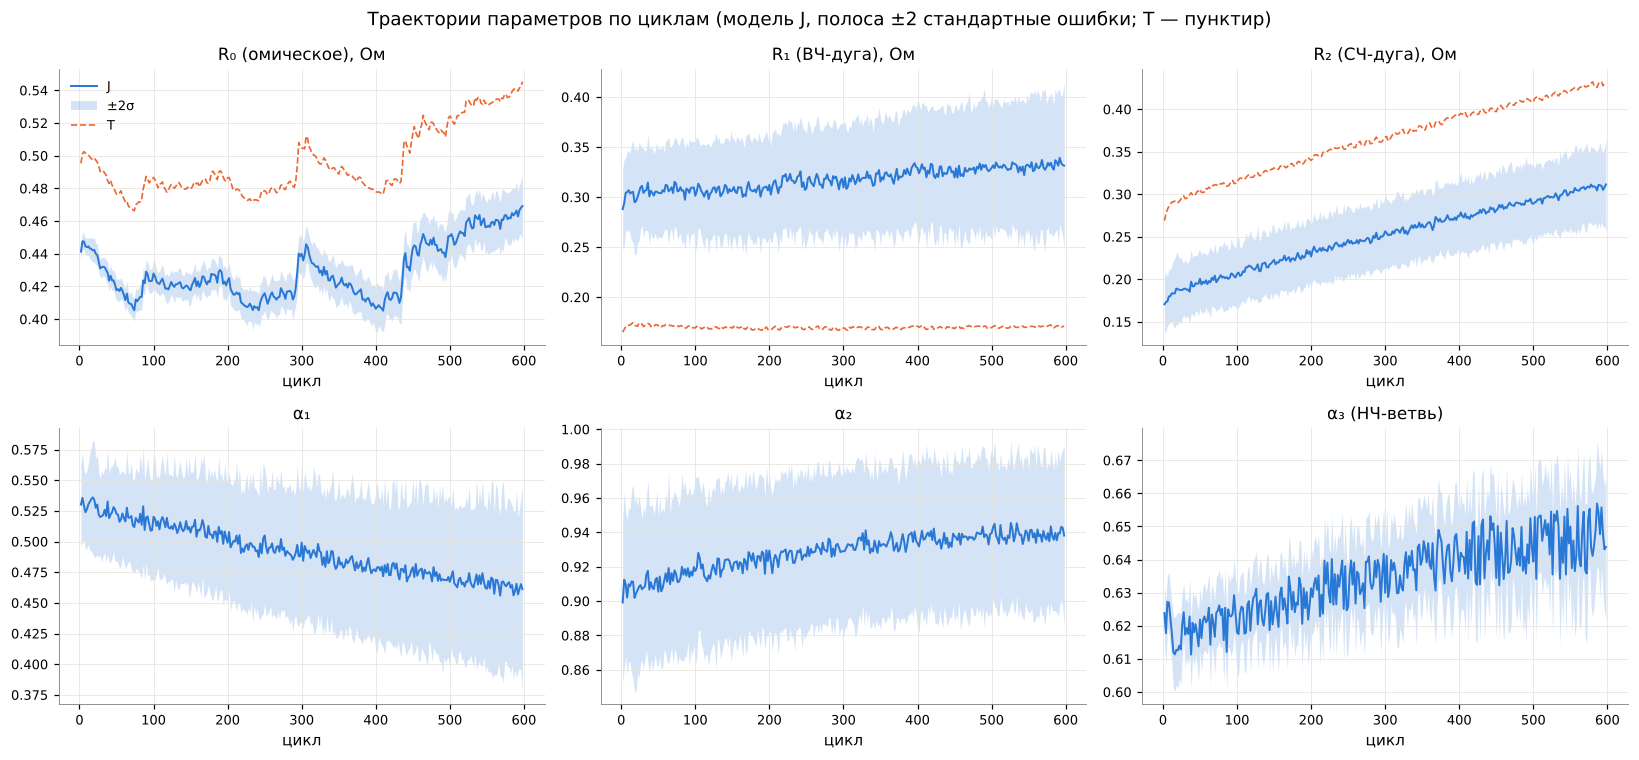

корреляция с ёмкостью: {'R0': -0.491, 'R1': -0.905, 'R2': -0.994, 'R1+R2': -0.993}


In [23]:
names = mBJ.names
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
panels = [("R0", "R₀ (омическое), Ом"), ("R1", "R₁ (ВЧ-дуга), Ом"), ("R2", "R₂ (СЧ-дуга), Ом"),
          ("alpha1", "α₁"), ("alpha2", "α₂"), ("alpha3", "α₃ (НЧ-ветвь)")]
for a, (p, lab) in zip(ax.ravel(), panels):
    j = names.index(p)
    a.plot(bat.cycles, TH["J"][:, j], color=PALETTE[0], lw=1.3, label="J")
    a.fill_between(bat.cycles, TH["J"][:, j] - 2 * SE["J"][:, j], TH["J"][:, j] + 2 * SE["J"][:, j],
                   color=PALETTE[0], alpha=0.2, lw=0, label="±2σ")
    if p in mBT.names:
        a.plot(bat.cycles, TH["T"][:, mBT.names.index(p)], "--", color=PALETTE[1], lw=1.1, label="T")
    a.set_title(lab); a.set_xlabel("цикл")
ax[0, 0].legend()
fig.suptitle("Траектории параметров по циклам (модель J, полоса ±2 стандартные ошибки; T — пунктир)")
fig.tight_layout(); savefig(fig, FIG / "battery_parameters.png"); plt.show()

Rsum = TH["J"][:, names.index("R1")] + TH["J"][:, names.index("R2")]
corr = {p: np.corrcoef(TH["J"][:, names.index(p)], bat.capacity)[0, 1] for p in ("R0", "R1", "R2")}
corr["R1+R2"] = np.corrcoef(Rsum, bat.capacity)[0, 1]
print("корреляция с ёмкостью:", {k: round(float(v), 3) for k, v in corr.items()})

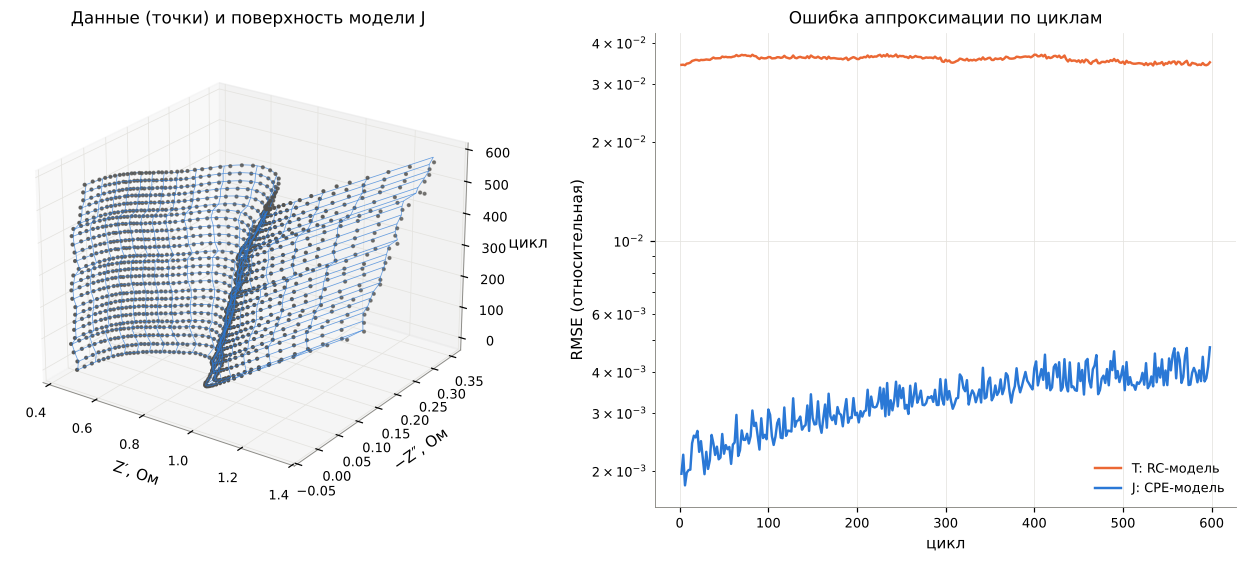

In [24]:
fig = plt.figure(figsize=(15, 5.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
wf = 2 * np.pi * np.logspace(np.log10(0.02), np.log10(2e4), 160)
sel = np.arange(0, 299, 12)
Zs = np.array([mBJ.predict(TH["J"][j], wf) for j in sel])
CY = np.repeat(bat.cycles[sel][:, None], len(wf), axis=1)
ax.plot_wireframe(Zs.real, -Zs.imag, CY, rstride=1, cstride=8, color=PALETTE[0], lw=0.5, alpha=0.7)
for j in sel:
    ax.scatter(bat.Z[j].real, -bat.Z[j].imag, np.full(60, bat.cycles[j]), s=3, color="#52514e")
ax.set_xlabel("Z′, Ом"); ax.set_ylabel("−Z″, Ом"); ax.set_zlabel("цикл")
ax.set_title("Данные (точки) и поверхность модели J"); ax.view_init(24, -55)
ax2 = fig.add_subplot(1, 2, 2)
ax2.semilogy(bat.cycles, RM["T"], color=PALETTE[1], label="T: RC-модель")
ax2.semilogy(bat.cycles, RM["J"], color=PALETTE[0], label="J: CPE-модель")
ax2.set_xlabel("цикл"); ax2.set_ylabel("RMSE (относительная)"); ax2.legend()
ax2.set_title("Ошибка аппроксимации по циклам")
savefig(fig, FIG / "battery_fit_3d.png"); plt.show()

**Наблюдения.** Учебная RC‑модель ошибается на 3,4–3,7 % с выраженной структурой невязок (идеальные полуокружности не повторяют сжатые дуги, а последовательный конденсатор $C_3$ даёт вертикальную, а не наклонную низкочастотную ветвь); CPE‑модель — на 0,2–0,5 %, т.е. на порядок лучше, и $\Delta\mathrm{BIC}\approx-670$ на первом цикле. Гипотеза H2 подтверждается. Показатель $\alpha_3\approx0{,}62$–$0{,}64$ близок к варбурговскому $1/2$ (полубесконечная диффузия) и медленно растёт. Сопротивление СЧ‑дуги $R_2$ (перенос заряда) растёт почти вдвое и сильнее всего связано с деградацией ёмкости; это согласуется с выводом Zhang et al. о значимости мнимой части импеданса в диапазоне единиц–десятков герц. Контрольные DE‑перезапуски не нашли заметно лучших минимумов, чем тёплый старт (относительное уменьшение $S$ напечатано выше), — траектории не застряли в локальных минимумах. Ступеньки $R_0$ около циклов 300 и 430 есть в обеих моделях, т.е. это особенность данных, а не артефакт подгонки. Широкая полоса $\pm2\sigma$ у $R_1$ и $R_2$ при гладких траекториях — следствие сильной корреляции оценок (раздел 7): каждая оценка неопределённа «вдоль хребта», а продолжение по циклам выбирает на хребте согласованную ветвь.

### 6.3 Полосковые резонаторы (источник `skrf`)

Каждая мода подгоняется в окне ±3 полосы пропускания моделями T и J (6 параметров: $f_r$, $Q$ или $\alpha$, комплексные $g$ и $d$). Затем проверяется прогноз утверждения 5: наклон $\ln Q$ по $\ln f$ по всем 12 модам трёх резонаторов.

In [25]:
rows, mode_fits = [], {}
for mm, d in res_data.items():
    ks = resonance.find_modes(d.freq, d.s21)
    fr0 = np.array([d.freq[k] for k in ks])
    f1 = np.median(np.diff(fr0)) if len(fr0) > 1 else fr0[0]
    for k in ks:
        T = resonance.fit_mode(d.freq, d.s21, k, "T")
        J = resonance.fit_mode(d.freq, d.s21, k, "J")
        n = resonance.mode_number(T.f_r, f1)
        mode_fits[(mm, n)] = (T, J)
        rows.append(dict(length_mm=mm, n=n, f_r_GHz=T.f_r / 1e9, Q_T=T.Q, se_Q_T=T.result.stderr[1],
                         alpha_J=J.result.theta[1], Q_J=J.Q, tan_delta=1 / J.Q, rmse_T=T.result.rmse,
                         rmse_J=J.result.rmse, dBIC=J.result.bic - T.result.bic, points=T.result.n // 2,
                         eps_eff=resonance.epsilon_eff(T.f_r, n, mm / 1000)))
modes = pd.DataFrame(rows)
modes.to_csv(RES / "resonator_modes.csv", index=False)
modes

,length_mm,n,f_r_GHz,Q_T,se_Q_T,alpha_J,Q_J,tan_delta,rmse_T,rmse_J,dBIC,points,eps_eff
0,36,1,1.9603,72.3794,0.2391,0.9912,72.6926,0.0138,0.0022,0.0022,4.9390e-05,11,4.5116
1,36,2,3.9276,74.1693,0.1402,0.9915,74.4826,0.0134,0.0020,0.0020,2.0661e-03,23,4.4956
2,72,2,1.9870,74.3059,0.0883,0.9915,74.6192,0.0134,0.0032,0.0032,-1.9545e-03,155,4.3913
3,72,3,2.9842,76.5325,0.0978,0.9917,76.8460,0.0130,0.0042,0.0042,-3.9090e-03,227,4.3803
4,72,4,3.9834,75.9785,0.0487,0.9917,76.2919,0.0131,0.0025,0.0025,1.7345e-02,311,4.3705
5,144,3,1.4872,72.1059,0.2131,0.9912,72.4191,0.0138,0.0067,0.0067,-4.5716e-04,113,4.4090
6,144,4,1.9847,73.2680,0.1801,0.9913,73.5812,0.0136,0.0065,0.0065,-2.8555e-03,155,4.4012
7,144,5,2.4817,74.1948,0.1387,0.9915,74.5081,0.0134,0.0056,0.0056,-5.5589e-03,191,4.3985
8,144,6,2.9809,75.5496,0.1390,0.9916,75.8630,0.0132,0.0060,0.0060,-9.8734e-03,227,4.3901
9,144,7,3.4785,74.7244,0.1053,0.9915,75.0377,0.0133,0.0051,0.0051,-1.6737e-02,263,4.3880


наклон d ln Q / d ln f = 0.024 ± 0.014 (1σ);  95% ДИ [-0.004, 0.053]
среднее tan δ_eff = 0.0134 ± 0.0002;  α = 0.99146
ε_eff по длинам: {36: {'mean': 4.504, 'std': 0.011}, 72: {'mean': 4.381, 'std': 0.01}, 144: {'mean': 4.393, 'std': 0.011}}


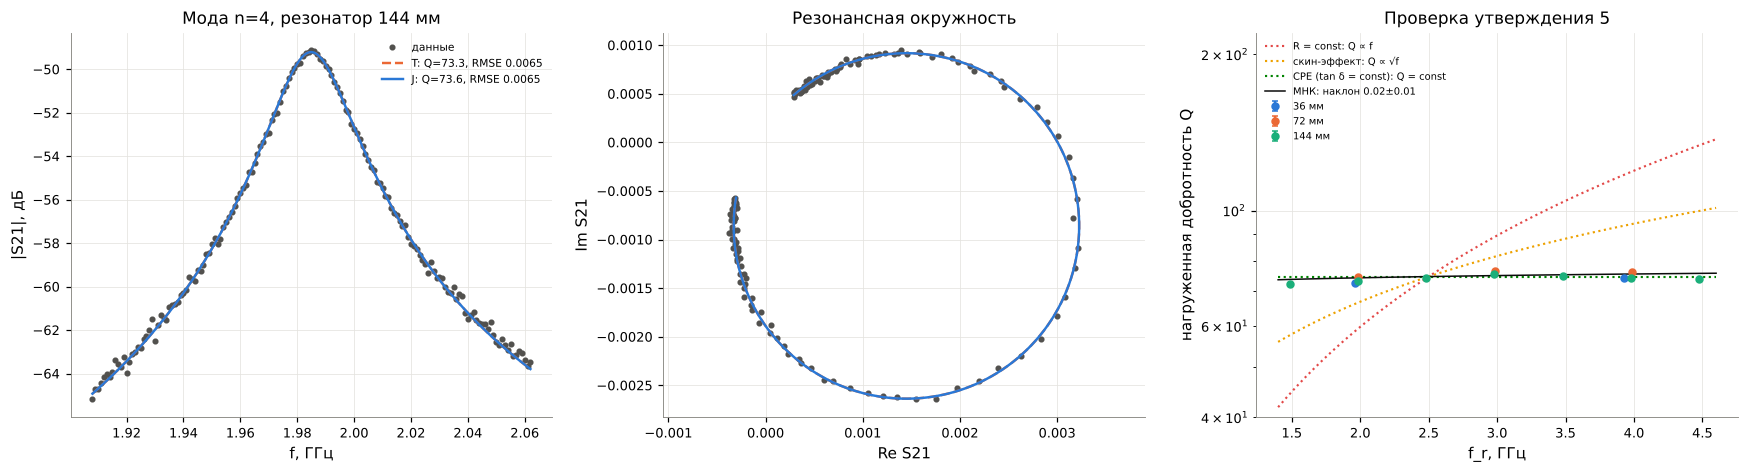

In [26]:
X = np.log(modes.f_r_GHz.values); Y = np.log(modes.Q_T.values)
wq = (modes.Q_T.values / modes.se_Q_T.values) ** 2           # веса 1/Var(ln Q)
A = np.vstack([X, np.ones_like(X)]).T
beta_hat, *_ = np.linalg.lstsq(A * np.sqrt(wq)[:, None], Y * np.sqrt(wq), rcond=None)
resid = Y - A @ beta_hat
s2 = np.sum(wq * resid**2) / (len(Y) - 2)
cov_b = s2 * np.linalg.inv(A.T @ (A * wq[:, None]))
slope, se_slope = beta_hat[0], np.sqrt(cov_b[0, 0])
print(f"наклон d ln Q / d ln f = {slope:.3f} ± {se_slope:.3f} (1σ);  95% ДИ [{slope - 1.96*se_slope:.3f}, {slope + 1.96*se_slope:.3f}]")
print(f"среднее tan δ_eff = {modes.tan_delta.mean():.4f} ± {modes.tan_delta.std(ddof=1):.4f};  "
      f"α = {modes.alpha_J.mean():.5f}")
print("ε_eff по длинам:", modes.groupby("length_mm").eps_eff.agg(["mean", "std"]).round(3).to_dict("index"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
mm, n = 144, 4
T, J = mode_fits[(mm, n)]
d = res_data[mm]; wnd = T.window
ff = np.linspace(d.freq[wnd][0], d.freq[wnd][-1], 600)
ax[0].plot(d.freq[wnd] / 1e9, 20*np.log10(np.abs(d.s21[wnd])), "o", ms=3, color="#52514e", label="данные")
for M, ls, col, lab in ((T, "--", PALETTE[1], "T"), (J, "-", PALETTE[0], "J")):
    ax[0].plot(ff / 1e9, 20*np.log10(np.abs(M.model.predict(M.result.theta, ff))), ls, color=col,
               label=f"{lab}: Q={M.Q:.1f}, RMSE {M.result.rmse:.4f}")
ax[0].set_xlabel("f, ГГц"); ax[0].set_ylabel("|S21|, дБ"); ax[0].legend(fontsize=7)
ax[0].set_title(f"Мода n={n}, резонатор {mm} мм")
ax[1].plot(d.s21[wnd].real, d.s21[wnd].imag, "o", ms=3, color="#52514e")
for M, ls, col in ((T, "--", PALETTE[1]), (J, "-", PALETTE[0])):
    sfit = M.model.predict(M.result.theta, ff); ax[1].plot(sfit.real, sfit.imag, ls, color=col)
ax[1].set_aspect("equal", adjustable="datalim"); ax[1].set_xlabel("Re S21"); ax[1].set_ylabel("Im S21")
ax[1].set_title("Резонансная окружность")
for k, mm in enumerate((36, 72, 144)):
    sub = modes[modes.length_mm == mm]
    ax[2].errorbar(sub.f_r_GHz, sub.Q_T, yerr=2 * sub.se_Q_T, fmt="o", color=PALETTE[k], label=f"{mm} мм", capsize=2)
fg = np.linspace(1.4, 4.6, 50); q0 = np.exp(beta_hat[1] + beta_hat[0] * np.log(2.5))
for s_, lab, col in ((1.0, "R = const: Q ∝ f", PALETTE[7]), (0.5, "скин-эффект: Q ∝ √f", PALETTE[3]),
                     (0.0, "CPE (tan δ = const): Q = const", PALETTE[5])):
    ax[2].plot(fg, q0 * (fg / 2.5) ** s_, ":", color=col, lw=1.4, label=lab)
ax[2].plot(fg, np.exp(beta_hat[1]) * fg ** slope, "-", color="#0b0b0b", lw=1, label=f"МНК: наклон {slope:.2f}±{se_slope:.2f}")
ax[2].set_xlabel("f_r, ГГц"); ax[2].set_ylabel("нагруженная добротность Q"); ax[2].set_ylim(40, 220)
ax[2].set_yscale("log"); ax[2].legend(fontsize=6.5); ax[2].set_title("Проверка утверждения 5")
fig.tight_layout(); savefig(fig, FIG / "fit_resonators.png"); plt.show()

**Наблюдения.** По отдельной моде модели T и J неразличимы: одинаковые RMSE, $|\Delta\mathrm{BIC}|<1$ — в узкой полосе $\pm3f_r/Q$ частотные зависимости $R=\mathrm{const}$ и $\omega^{-\alpha}\cos(\alpha\pi/2)/Q$ совпадают в первом порядке (это иллюстрация утверждения 6: идентифицируемость определяется полосой данных). Различие появляется **между модами**: наклон $\ln Q$ по $\ln f$ близок к нулю и исключает $s=1$ (сосредоточенное $R$) и $s=1/2$ (чистый скин‑эффект), как предсказывает модель J с диэлектриком постоянного угла потерь. Гипотеза H3 подтверждается. Эффективная проницаемость $\varepsilon_{\rm eff}\approx4{,}4$ согласована между длинами 72 и 144 мм; у короткого резонатора она выше на ~2 % — влияние краевых полей $\Delta\ell$, которыми мы пренебрегли (IPC‑TM‑650 2.5.5.5).

## 7. Ошибки аппроксимации и сравнение моделей

In [27]:
summary = []
for c in circuits:
    t_, j_ = fits_c[(c.name, "T")], fits_c[(c.name, "J")]
    summary.append(dict(источник="impedancepy", объект=c.name, N=len(c.freq), k_T=t_.k, k_J=j_.k,
                        RMSE_T=t_.rmse, RMSE_J=j_.rmse, dBIC=j_.bic - t_.bic, cond_J=j_.cond))
for j in (0, 149, 298):
    t_, j_ = track["T"][j], track["J"][j]
    summary.append(dict(источник="zhang2020", объект=f"35C02, цикл {bat.cycles[j]}", N=60, k_T=t_.k, k_J=j_.k,
                        RMSE_T=t_.rmse, RMSE_J=j_.rmse, dBIC=j_.bic - t_.bic, cond_J=j_.cond))
for (mm, n), (T, J) in sorted(mode_fits.items()):
    if n in (2, 4):
        summary.append(dict(источник="skrf", объект=f"{mm} мм, мода {n}", N=T.result.n // 2, k_T=6, k_J=6,
                            RMSE_T=T.result.rmse, RMSE_J=J.result.rmse, dBIC=J.result.bic - T.result.bic,
                            cond_J=J.result.cond))
summary = pd.DataFrame(summary)
summary.to_csv(RES / "model_comparison.csv", index=False)
summary

,источник,объект,N,k_T,k_J,RMSE_T,RMSE_J,dBIC,cond_J
0,impedancepy,Circuit1_EIS_1,48,4,5,0.0007,0.0004,-110.3452,11.4977
1,impedancepy,Circuit1_EIS_2,48,4,5,0.0007,0.0004,-101.1730,11.4970
2,impedancepy,Circuit2_EIS_1,56,4,5,0.0025,0.0019,-55.9440,18.5734
3,impedancepy,Circuit2_EIS_2,56,4,5,0.0025,0.0020,-50.1518,18.5665
4,impedancepy,Circuit3_EIS_1,53,4,5,0.0014,0.0010,-51.3440,13.9748
5,impedancepy,Circuit3_EIS_2,53,4,5,0.0015,0.0011,-57.4540,13.9779
6,zhang2020,"35C02, цикл 2",60,7,10,0.0343,0.0020,-672.2397,200.1369
7,zhang2020,"35C02, цикл 300",60,7,10,0.0355,0.0038,-522.8178,172.1792
8,zhang2020,"35C02, цикл 598",60,7,10,0.0349,0.0048,-464.2281,169.1165
9,skrf,"36 мм, мода 2",23,6,6,0.0020,0.0020,0.0021,4.5560


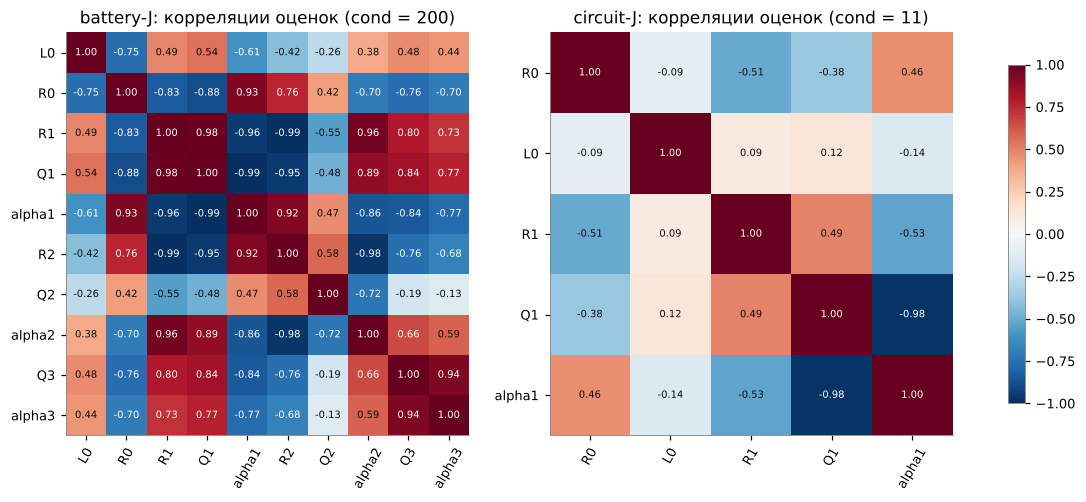

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (key, r) in zip(ax, (("battery-J", track["J"][0]), ("circuit-J", fits_c[("Circuit1_EIS_1", "J")]))):
    im = a.imshow(r.corr, cmap=plt.get_cmap("RdBu_r"), vmin=-1, vmax=1)
    a.set_xticks(range(r.k)); a.set_yticks(range(r.k))
    a.set_xticklabels(r.names, rotation=60); a.set_yticklabels(r.names); a.grid(False)
    for i in range(r.k):
        for j in range(r.k):
            a.text(j, i, f"{r.corr[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                   color="white" if abs(r.corr[i, j]) > 0.6 else "#0b0b0b")
    a.set_title(f"{key}: корреляции оценок (cond = {r.cond:.0f})")
fig.colorbar(im, ax=ax, shrink=0.8)
savefig(fig, FIG / "parameter_correlations.png"); plt.show()

Матрицы корреляций оценок (аппроксимация Лапласа) показывают, какие комбинации параметров данные различают плохо. В тестовой цепи связана только пара $(Q_1,\alpha_1)$ ($\rho\approx-0{,}98$: на ограниченной полосе изменение $\alpha$ частично компенсируется изменением $Q$), обусловленность ~10. В модели батареи две перекрывающиеся дуги «делят» сопротивление: $\rho(R_1,R_2)\approx-0{,}99$, сильно связаны и $(R_1,Q_1,\alpha_1,\alpha_2)$. Модель локально идентифицируема (обусловленность нормированного якобиана ~200, ковариация конечна), но плохо обусловленное направление лежит вдоль «хребта» $R_1+R_2\approx\mathrm{const}$. Поэтому физически надёжная величина — суммарное сопротивление дуг $R_1+R_2$, а не каждое слагаемое:

In [29]:
rows = []
for j in (0, 149, 298):
    r = track["J"][j]
    i1, i2 = r.names.index("R1"), r.names.index("R2")
    a = np.zeros(r.k); a[[i1, i2]] = 1.0
    se_sum = float(np.sqrt(a @ r.cov @ a))
    rows.append({"цикл": bat.cycles[j], "R1": r.theta[i1], "σ(R1)/R1, %": 100 * r.rel_stderr[i1],
                 "R2": r.theta[i2], "σ(R2)/R2, %": 100 * r.rel_stderr[i2], "R1+R2": r.theta[i1] + r.theta[i2],
                 "σ(R1+R2)/(R1+R2), %": 100 * se_sum / (r.theta[i1] + r.theta[i2]), "ρ(R1,R2)": r.corr[i1, i2]})
pd.DataFrame(rows).set_index("цикл")

,R1,"σ(R1)/R1, %",R2,"σ(R2)/R2, %",R1+R2,"σ(R1+R2)/(R1+R2), %","ρ(R1,R2)"
цикл,,,,,,,
2,0.2880,6.9380,0.1706,9.5115,0.4586,0.9398,-0.9931
300,0.3096,10.2157,0.2564,8.7359,0.5660,1.8026,-0.9866
598,0.3315,12.6665,0.3115,8.6472,0.6430,2.5496,-0.9813


## 8. Временная область: уравнения в 3D с учётом времени

### 8.1 От учебной к журнальной модели: ток при скачке напряжения

Поверхность $i(t,\alpha)$ — решение дробного уравнения (J) схемой Грюнвальда–Летникова при $\beta=1$, $\alpha\in[0{,}6;\,1]$ и $Q_\alpha=C\,\omega_0^{1-\alpha}$ (тот же модуль импеданса ёмкостного элемента на $\omega_0$); край $\alpha=1$ — учебное ОДУ (T), совпадение с LSODA показано линией. Уменьшение $\alpha$ превращает затухающие колебания в монотонную релаксацию с «тяжёлым хвостом» (память дробного интеграла).

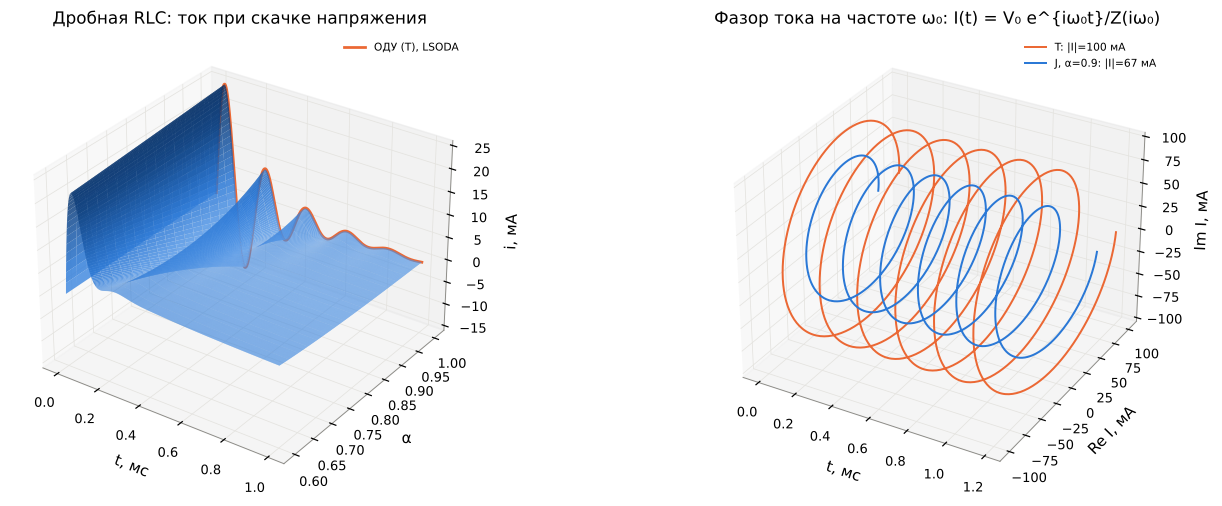

max |GL(α=1) − LSODA| = 0.00019083638087484187 А


In [30]:
tg = np.linspace(0, 1e-3, 6001)
alphas = np.linspace(0.6, 1.0, 17)
w0 = 1 / np.sqrt(L_ * C_)
# Q_α = C ω₀^{1−α}: CPE с тем же модулем импеданса на ω₀, что и конденсатор C (сравнимое семейство)
I = np.array([td.gl_series_rlc(R_, L_, C_ * w0 ** (1 - a), lambda x: np.where(x > 0, V0, 0.0), tg, alpha=a)["i"]
              for a in alphas])
sol = td.ode_series_rlc(R_, L_, C_, lambda tt: V0, tg, method="LSODA")
fig = plt.figure(figsize=(15, 5.4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
TT, AA = np.meshgrid(tg * 1e3, alphas)
ax.plot_surface(TT, AA, I * 1e3, cmap=BLUES, lw=0, antialiased=True, alpha=0.85, rstride=1, cstride=15)
ax.plot(tg * 1e3, np.ones_like(tg), sol.y[1] * 1e3, color=PALETTE[1], lw=1.8, label="ОДУ (T), LSODA")
ax.set_xlabel("t, мс"); ax.set_ylabel("α"); ax.set_zlabel("i, мА"); ax.legend(fontsize=7)
ax.set_title("Дробная RLC: ток при скачке напряжения"); ax.view_init(30, -55)

# установившийся гармонический режим: фазор тока в 3D (t, Re, Im) для T и J
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
tt = np.linspace(0, 6 * 2 * np.pi / w0, 1200)
for (lab, Zc, col) in (("T", R_ + 1j * w0 * L_ + 1 / (1j * w0 * C_), PALETTE[1]),
                       ("J, α=0.9", R_ + 1j * w0 * L_ + 1 / (C_ * w0 ** 0.1 * (1j * w0) ** 0.9), PALETTE[0])):
    Iph = V0 / Zc * np.exp(1j * w0 * tt)
    ax2.plot(tt * 1e3, Iph.real * 1e3, Iph.imag * 1e3, color=col, lw=1.3, label=f"{lab}: |I|={abs(V0/Zc)*1e3:.0f} мА")
ax2.set_xlabel("t, мс"); ax2.set_ylabel("Re I, мА"); ax2.set_zlabel("Im I, мА"); ax2.legend(fontsize=7)
ax2.set_title("Фазор тока на частоте ω₀: I(t) = V₀ e^{iω₀t}/Z(iω₀)")
savefig(fig, FIG / "time_3d_rlc.png"); plt.show()
print("max |GL(α=1) − LSODA| =", np.abs(I[-1] - sol.y[1]).max(), "А")

### 8.2 Литий‑ионный элемент: отклик напряжения на ступень тока по циклам

Ступень тока 1C = 45 мА; $\Delta v(t)=\mathcal L^{-1}\{Z(s)I_0/s\}(t)$ для оценённых параметров модели J каждого 25‑го цикла (Талбот, 48 моментов времени от 10 мкс до 1000 с на логарифмической сетке). Индуктивность вклада при $t>0$ не даёт. Медленная ось — старение, быстрая — время после включения тока. Справа: отклики моделей T и J на цикле 2. Хотя спектры моделей различаются лишь на несколько процентов, при $t\gtrsim10$ с отклики расходятся кратно: последовательный конденсатор модели T даёт линейный рост $I_0t/C_3$, CPE — степенной $\propto t^{\alpha_3}$. Экстраполяция на $t\gtrsim 10^2$ с выходит за допущение (A1): за это время меняются степень заряженности и ЭДС элемента, которых линейная модель не содержит.

Талбот: 576 обращений за 15.9 с


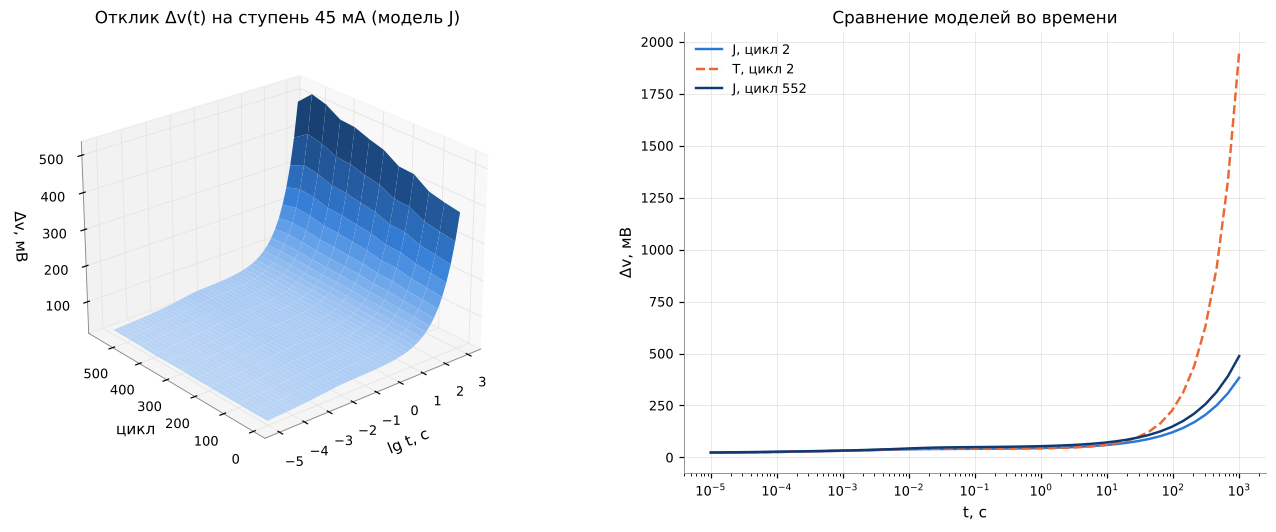

In [31]:
I0 = 0.045
tlog = np.logspace(-5, 3, 48)
csel = np.arange(0, 299, 25)
t0 = time.perf_counter()
Vsurf = np.array([td.step_voltage(mBJ, TH["J"][j], tlog, I0=I0) for j in csel])
print(f"Талбот: {Vsurf.size} обращений за {time.perf_counter() - t0:.1f} с")
vT = td.step_voltage(mBT, TH["T"][0], tlog, I0=I0)
fig = plt.figure(figsize=(15, 5.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
LT, CY = np.meshgrid(np.log10(tlog), bat.cycles[csel])
ax.plot_surface(LT, CY, Vsurf * 1e3, cmap=BLUES, lw=0, alpha=0.95)
ax.set_xlabel("lg t, с"); ax.set_ylabel("цикл"); ax.set_zlabel("Δv, мВ")
ax.set_title("Отклик Δv(t) на ступень 45 мА (модель J)"); ax.view_init(25, -130)
ax2 = fig.add_subplot(1, 2, 2)
ax2.semilogx(tlog, Vsurf[0] * 1e3, color=PALETTE[0], label="J, цикл 2")
ax2.semilogx(tlog, vT * 1e3, "--", color=PALETTE[1], label="T, цикл 2")
ax2.semilogx(tlog, Vsurf[-1] * 1e3, color=BLUES(0.95), label=f"J, цикл {bat.cycles[csel[-1]]}")
ax2.set_xlabel("t, с"); ax2.set_ylabel("Δv, мВ"); ax2.legend(); ax2.set_title("Сравнение моделей во времени")
savefig(fig, FIG / "battery_time_3d.png"); plt.show()

### 8.3 Резонатор: затухание моды

Импульсный отклик эквивалентного последовательного контура моды $n=4$ резонатора 144 мм: комплексная огибающая $h(t)\propto e^{-\omega_r t/(2Q)}e^{i\omega_r t}$ в 3D $(t,\operatorname{Re}h,\operatorname{Im}h)$ — спираль с постоянной времени $\tau=2Q/\omega_r$.

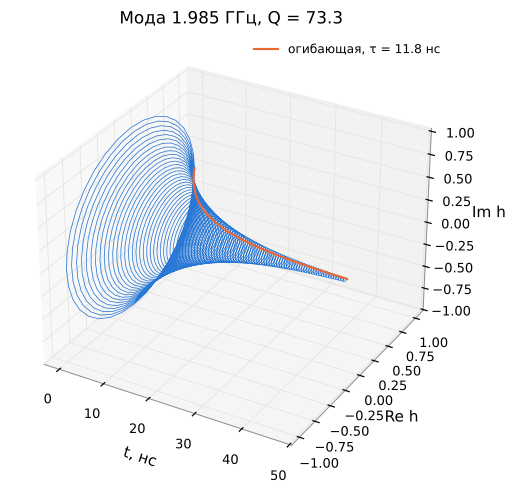

In [32]:
T, J = mode_fits[(144, 4)]
wr = 2 * np.pi * T.f_r; tau = 2 * T.Q / wr
th = np.linspace(0, 4 * tau, 3000)
h = np.exp(-th / tau) * np.exp(1j * wr * th)
fig = plt.figure(figsize=(7.5, 5.2))
ax = fig.add_subplot(projection="3d")
ax.plot(th * 1e9, h.real, h.imag, lw=0.5, color=PALETTE[0])
ax.plot(th * 1e9, np.exp(-th / tau), np.zeros_like(th), color=PALETTE[1], lw=1.4, label=f"огибающая, τ = {tau*1e9:.1f} нс")
ax.set_xlabel("t, нс"); ax.set_ylabel("Re h"); ax.set_zlabel("Im h"); ax.legend(fontsize=8)
ax.set_title(f"Мода {T.f_r/1e9:.3f} ГГц, Q = {T.Q:.1f}")
savefig(fig, FIG / "resonator_time_3d.png"); plt.show()

In [33]:
key = {
    "circuits_rmse_T_median": float(np.median([fits_c[(c.name, 'T')].rmse for c in circuits])),
    "circuits_rmse_J_median": float(np.median([fits_c[(c.name, 'J')].rmse for c in circuits])),
    "circuits_dBIC_J_minus_T": [round(fits_c[(c.name, 'J')].bic - fits_c[(c.name, 'T')].bic, 1) for c in circuits],
    "circuits_alpha1": [round(fits_c[(c.name, 'J')].params['alpha1'], 5) for c in circuits],
    "battery_rmse_T_median": float(np.median(RM["T"])), "battery_rmse_J_median": float(np.median(RM["J"])),
    "battery_dBIC_cycle2": float(track["J"][0].bic - track["T"][0].bic),
    "battery_R2_first_last": [float(TH["J"][0, names.index("R2")]), float(TH["J"][-1, names.index("R2")])],
    "battery_R0_first_last": [float(TH["J"][0, names.index("R0")]), float(TH["J"][-1, names.index("R0")])],
    "battery_corr_with_capacity": {k: float(v) for k, v in corr.items()},
    "resonator_slope_lnQ_lnf": [float(slope), float(se_slope)],
    "resonator_tan_delta_mean": float(modes.tan_delta.mean()),
    "resonator_eps_eff": modes.groupby("length_mm").eps_eff.mean().round(3).to_dict(),
}
(RES / "summary.json").write_text(json.dumps(key, ensure_ascii=False, indent=1))
key

{'circuits_rmse_T_median': 0.0014327136246120179, 'circuits_rmse_J_median': 0.0010836143690637044, 'circuits_dBIC_J_minus_T': [-110.3, -101.2, -55.9, -50.2, -51.3, -57.5], 'circuits_alpha1': [0.99704, 0.99718, 0.99373, 0.99393, 0.99691, 0.99642], 'battery_rmse_T_median': 0.035861020717960906, 'battery_rmse_J_median': 0.0033799361979753692, 'battery_dBIC_cycle2': -672.2396893493105, 'battery_R2_first_last': [0.17059888125104455, 0.31149871679106317], 'battery_R0_first_last': [0.44132068084205434, 0.4691789714961612], 'battery_corr_with_capacity': {'R0': -0.4912709001769468, 'R1': -0.9053501324891763, 'R2': -0.9939002724929414, 'R1+R2': -0.9933437799379456}, 'resonator_slope_lnQ_lnf': [0.024364765833463448, 0.014432425046739883], 'resonator_tan_delta_mean': 0.013412935579889559, 'resonator_eps_eff': {36: 4.504, 72: 4.381, 144: 4.393}}

## 9. Структура для смешанных моделей и лабораторных 2–3

Модуль `rlcfreq.perturb` содержит заготовки для следующих работ:

* **ЛР 2 (возмущение данных):** `perturb_data(Z, kind, level)` — мультипликативный и аддитивный шум, выбросы, дрейф по частоте; `jitter_frequency` — ошибка оси частот (в т.ч. для проверки допущения о сетке `zhang2020`).
* **ЛР 3 (возмущение модели):** `structural_neighbours(circuit)` — все допустимые схемы на расстоянии одного изменения (замена $C\leftrightarrow Q$, $L\leftrightarrow L_f$, удаление элемента, добавление последовательной $L$). Среди соседей естественно возникают **смешанные модели** — часть элементов идеальна, часть дробная.

Демонстрация: жадный поиск структуры по BIC, начиная с учебной модели батареи (цикл 2). На каждом шаге подгоняются все соседи (multistart TRF), выбирается лучший по BIC; остановка, когда улучшение $<2$. Это одношаговый вариант поиска допустимой суперпозиции из лекции о символьной регрессии: множество примитивов $G=\{R,L,C,Q,L_f\}$, правила порождения — замены и удаления, критерий — BIC.

In [34]:
from rlcfreq import perturb
spec_pool = {**models.battery_model("T").specs, **models.battery_model("J").specs}

def make(circ):
    names = circuit.parameter_names(circuit.parse(circ))
    return models.ImpedanceModel(circ, specs={n: spec_pool[n] for n in names if n in spec_pool})

current = mBT.circuit
best = fitting.fit(make(current), w_b, bat.Z[0], method="multistart", seed=SEED)
path = [dict(шаг=0, изменение="старт (T)", схема=current, k=best.k, RMSE=best.rmse, BIC=best.bic)]
t0 = time.perf_counter()
for step in range(1, 6):
    cands = []
    for circ, what in perturb.structural_neighbours(current):
        r = fitting.fit(make(circ), w_b, bat.Z[0], method="multistart", seed=SEED)
        cands.append((r.bic, circ, what, r))
    cands.sort(key=lambda c: c[0])
    bic, circ, what, r = cands[0]
    if bic > best.bic - 2:
        break
    current, best = circ, r
    path.append(dict(шаг=step, изменение=what, схема=circ, k=r.k, RMSE=r.rmse, BIC=r.bic))
print(f"поиск структуры: {time.perf_counter() - t0:.0f} с; итог: {current}"
      f"{'  (= журнальная модель J)' if current == mBJ.circuit else ''}")
pd.DataFrame(path).set_index("шаг")

поиск структуры: 29 с; итог: L0-R0-p(R1,Q1)-p(R2,Q2)-Q3  (= журнальная модель J)


,изменение,схема,k,RMSE,BIC
шаг,,,,,
0,старт (T),"L0-R0-p(R1,C1)-p(R2,C2)-C3",7,0.0343,-776.0457
1,C3 → Q3,"L0-R0-p(R1,C1)-p(R2,C2)-Q3",8,0.0133,-998.5271
2,C1 → Q1,"L0-R0-p(R1,Q1)-p(R2,C2)-Q3",9,0.0022,-1422.5455
3,C2 → Q2,"L0-R0-p(R1,Q1)-p(R2,Q2)-Q3",10,0.0020,-1448.2853


In [35]:
# пример возмущения данных (задел ЛР 2): устойчивость оценок модели J к шуму 0,5 %
rows = []
for seed in range(10):
    Zp = perturb.perturb_data(bat.Z[0], "multiplicative", 5e-3, seed=seed)
    r = fitting.fit(mBJ, w_b, Zp, theta0=track["J"][0].theta, method="trf")
    rows.append(r.theta)
rows = np.array(rows)
pd.DataFrame({"исходная оценка": track["J"][0].theta, "среднее по 10 возмущениям": rows.mean(0),
              "разброс (σ)": rows.std(0, ddof=1), "σ Лапласа": track["J"][0].stderr}, index=mBJ.names)

,исходная оценка,среднее по 10 возмущениям,разброс (σ),σ Лапласа
L0,4.6259e-07,4.6708e-07,1.0708e-08,8.0311e-09
R0,4.4132e-01,4.4012e-01,1.7056e-03,2.5419e-03
R1,2.8798e-01,2.8865e-01,1.3757e-02,1.9980e-02
Q1,4.1968e-02,4.2565e-02,3.1068e-03,6.1077e-03
alpha1,5.3010e-01,5.2734e-01,5.6627e-03,1.6585e-02
R2,1.7060e-01,1.7128e-01,1.3422e-02,1.6226e-02
Q2,3.8477e-02,3.8914e-02,1.4866e-03,1.3410e-03
alpha2,8.9918e-01,8.9691e-01,2.3346e-02,2.3522e-02
Q3,1.0900e+01,1.0896e+01,1.4342e-01,1.3094e-01
alpha3,6.2387e-01,6.2348e-01,4.8088e-03,4.4083e-03


Разброс оценок по 10 реализациям мультипликативного шума 0,5 % того же порядка, что и стандартные ошибки Лапласа (они рассчитаны по остаточной ошибке ≈0,2 %), а среднее не смещено относительно исходной оценки больше чем на σ. Систематическое исследование зависимости от уровня и типа возмущения (выбросы, дрейф, ошибка оси частот) — задача ЛР 2; возмущение структуры (соседние схемы выше) — ЛР 3.

## 10. Выводы

1. **Модель и её модификация.** Из ОДУ $L\ddot q+R\dot q+q/C=v$ символьно получен импеданс $Z_T(s)=R+sL+1/(sC)$; журнальная модификация (дробные $L^{\beta}C^{\alpha}$ / CPE) вкладывает учебную модель как частный случай $\alpha=\beta=1$. Доказаны пассивность при $\alpha,\beta\le1$, единственность и формула резонанса, частотная независимость $\tan\delta=\cot(\alpha\pi/2)$, закон $Q_n\propto\omega_n/\alpha_{\rm att}(\omega_n)$ для мод линии, идентифицируемость с точностью до перестановок RC‑блоков; для поля вынужденной цепи в $\mathbb R^3$ получены $\operatorname{div}F=-2\zeta$, $\operatorname{rot}F=(u\sin\varphi,0,-2)$ и теорема Лиувилля (проверены численно до $10^{-10}$).
2. **Представления.** Одна и та же модель записана строкой грамматики, деревом разбора, выражением SymPy, графом цепи (узловой анализ даёт тот же $Z(s)$), передаточной функцией (только целый порядок), DAG суперпозиции с общими подграфами, словарём и позиционной матрицей связей; все кодировки взаимно обратимы (тесты). Символьное представление окупается практически: из него получен точный аналитический якобиан, с которым TRF/LM сходятся за ~35 вычислений модели, тогда как глобальным методам нужно $10^3$–$10^5$.
3. **Тестовые цепи (H1).** Учебная модель с паразитной индуктивностью описывает физические цепи с относительной ошибкой 0,07–0,25 %; CPE с $\hat\alpha=0{,}994$–$0{,}997$ уменьшает ошибку до 0,04–0,2 % ($\Delta$BIC от −50 до −110) — диэлектрическая абсорбция реальных конденсаторов. Дробная катушка не нужна ($\hat\beta\to1$). Повторы воспроизводятся до долей процента. Остаточная невязка на высоких частотах указывает на ошибку модели наблюдения.
4. **Li‑ion элемент (H2).** Учебная RC‑модель ошибается на ~3,6 % при любом числе циклов, CPE‑модель — на 0,2–0,5 % ($\Delta$BIC ≈ −670 на цикле 2). Сопротивление переноса заряда $R_2$ растёт с 0,17 до 0,31 Ом за 598 циклов и коррелирует с ёмкостью ($\rho=-0{,}99$); надёжно оценивается сумма $R_1+R_2$, а не разбиение между перекрывающимися дугами. Жадный поиск структуры по BIC от учебной модели сам приходит к журнальной модели через смешанные модели.
5. **Резонаторы (H3).** По одной моде модели неразличимы ($|\Delta\mathrm{BIC}|<1$), но по 12 модам наклон $d\ln Q/d\ln f=0{,}02\pm0{,}01$ исключает сосредоточенное $R$ ($s=1$) и скин‑эффект ($s=1/2$) и согласуется с CPE ($s=0$): $\tan\delta_{\rm eff}\approx0{,}0134$, $\varepsilon_{\rm eff}\approx4{,}4$.
6. **Солверы и оптимизаторы.** Для целого порядка — LSODA (жёсткие задачи), для дробного — Грюнвальд–Летников ($O(h)$, проверка «время → частота» по lock‑in) и обращение Лапласа по Талботу (точность $10^{-12}$, многомасштабные отклики). Оптимизация: DE для старта, TRF/LM с символьным якобианом для уточнения и продолжения по циклам; все пять методов сходятся к одному минимуму.

**Ограничения.** Сетка частот `zhang2020` восстановлена (явное допущение, проверенное по опубликованным частотам); шум предполагается пропорциональным $|Z|$; линейная модель батареи неприменима на временах, где меняется степень заряженности; для резонаторов не учтено удлинение краевыми полями.

## Источники

1. Zhang Y., Tang Q., Zhang Y., Wang J., Stimming U., Lee A. A. Identifying degradation patterns of lithium ion batteries from impedance spectroscopy using machine learning // *Nature Communications*. 2020. Vol. 11. Art. 1706. doi:10.1038/s41467-020-15235-7. Данные: doi:10.5281/zenodo.3633835; код: https://github.com/YunweiZhang/ML-identify-battery-degradation
2. Wang S., Zhang J., Gharbi O., Vivier V., Gao M., Orazem M. E. Electrochemical impedance spectroscopy // *Nature Reviews Methods Primers*. 2021. Vol. 1. Art. 41. doi:10.1038/s43586-021-00039-w
3. Westerlund S., Ekstam L. Capacitor theory // *IEEE Trans. Dielectrics and Electrical Insulation*. 1994. Vol. 1, no. 5. P. 826–839. doi:10.1109/94.326654
4. Radwan A. G., Salama K. N. Passive and active elements using fractional $L_\beta C_\alpha$ circuit // *IEEE Trans. Circuits and Systems I*. 2011. Vol. 58, no. 10. P. 2388–2397.
5. Murbach M. D., Gerwe B., Dawson-Elli N., Tsui L. impedance.py: A Python package for electrochemical impedance analysis // *Journal of Open Source Software*. 2020. Vol. 5, no. 52. Art. 2349. doi:10.21105/joss.02349. Данные: https://github.com/ECSHackWeek/impedance.py
6. Arsenovic A., Hillairet J., Anderson J., Forstén H., Rieß V., Eller M., Sauber N., Weikle R., Barnhart W., Forstmayr F. scikit-rf: An open source Python package for microwave network creation, analysis, and calibration // *IEEE Microwave Magazine*. 2022. Vol. 23, no. 1. P. 98–105. doi:10.1109/MMM.2021.3117139. Данные: https://github.com/scikit-rf/scikit-rf
7. Orazem M. E., Tribollet B. *Electrochemical Impedance Spectroscopy*. Wiley, 2008 (весовые функции, CPE).
8. Pozar D. M. *Microwave Engineering*, 4th ed. Wiley, 2012, гл. 6 (резонаторы на отрезках линий).
9. Podlubny I. *Fractional Differential Equations*. Academic Press, 1999 (схема Грюнвальда–Летникова).
10. Abate J., Valkó P. P. Multi-precision Laplace transform inversion // *Int. J. Numer. Methods Eng.* 2004. Vol. 60. P. 979–993 (метод Талбота, реализация `mpmath`).
11. Self S. G., Liang K.-Y. Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions // *JASA*. 1987. Vol. 82. P. 605–610.
12. IPC-TM-650, method 2.5.5.5. Stripline test for permittivity and loss tangent (dielectric constant and dissipation factor) at X-band. IPC.
13. Материалы курса: Strijov V. *Causal structure learning with symbolic regression*; *Causal graphs and optimization*; *Causal inference in latent space* — https://github.com/vadim-vic/Causal-Inference/tree/main/slides